# FastVUS: A scalable and adaptive time series anomaly detection metric

## Setup

In [58]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import os
from matplotlib.gridspec import GridSpec
from itertools import combinations

from tqdm import tqdm
from tqdm.notebook import tqdm_notebook
tqdm_notebook.pandas()

experiments_path = os.path.join('..', '..', 'experiments')
save_fig_path = os.path.join(experiments_path, 'figures')
os.makedirs(save_fig_path, exist_ok=True)

In [59]:
# Consistent color palette
my_vus_name = 'FastVUS'

color_palette = {
    f'{my_vus_name} (L: 128)': '#c8b400',          # Good
    f'{my_vus_name}-GPU (L: 128)': '#40da70',     # Very Good
    f'{my_vus_name}': '#c8b400',          # Good
    f'{my_vus_name}-GPU': '#40da70',     # Very Good
    'AUC': '#f1a73f',                # Secondary competitor
    'VUS (L: 128)': '#b02a41',            # Main competitor
    'Affiliation': '#A5D1C2',        # Useless competitors
    'Range-AUC (L: 128)': '#547C6E',       # Useless competitors
    'RF': '#123327',                    # Useless competitors
}

# Map shorthand names to formal names
formal_names = {
    'FF-VUS': f'{my_vus_name} (L: 128)',
    'FF-VUS-GPU': f'{my_vus_name}-GPU (L: 128)',
    'AUC': 'AUC',
    'VUS': 'VUS (L: 128)',
    'RF': 'RF',
    'AFFILIATION': 'Affiliation',
    'RANGE-AUC': 'Range-AUC (L: 128)',
    'auc': 'AUC',
    'vus': 'VUS (L: 128)',
    'ffvus': f'{my_vus_name} (L: 128)',
    'ffvusgpu': f'{my_vus_name}-GPU (L: 128)',
}

# Default seaborn style
sns.set_style("whitegrid")

In [60]:
def finalize_plot(save_dir, filename):
    plt.tight_layout()
    if filename is not None:
        save_path = os.path.join(save_dir, filename)
        # plt.savefig(f"{save_path}.svg", bbox_inches='tight')
        plt.savefig(f"{save_path}.pdf", bbox_inches='tight', pad_inches=0)
    plt.show()

def load_results(path):
    result_files = [file for file in os.listdir(path) if file.endswith('.csv')]

    df = pd.DataFrame()
    for file in tqdm(result_files):
        file_path = os.path.join(path, file)
        curr_df = pd.read_csv(file_path, index_col=0).reset_index()
        df = pd.concat([df, curr_df], ignore_index=True)
    return df


## Experiment 1: All metrics with default parameters on the TSB-UAD benchmark

In [61]:
curr_experiment_path = os.path.join(experiments_path, 'all_metrics_tsb_def_params', 'results')
df = load_results(curr_experiment_path)
df['Metric'] = df['Metric'].map(formal_names)
df.sample(3)

100%|██████████| 7/7 [00:00<00:00, 14.13it/s]


,Time series,Length,Number of anomalies,Anomalies average length,Detector,Slope size,Metric,Metric value,Metric time,Existence,...,Safe mask time,Thresholds time,n_thresholds,Score mask time,Position time,Slopes time,Existence time,Confusion matrix time,Precision recall curve time,Integral time
78638,157_Stock_id_9_Finance_tr_500_1st_19.csv,10000,1200,1.16,MatrixProfile,NaN,Affiliation,0.519079,0.512970,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
97309,820_Exathlon_id_11_Facility_tr_11665_1st_13484...,46660,3,976.00,TimesNet,NaN,Affiliation,0.783076,0.003443,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
20407,732_YAHOO_id_182_Synthetic_tr_500_1st_658.csv,1421,2,2.00,Sub_KNN,128.0,Range-AUC (L: 128),0.917477,0.002777,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Runtime Box plots

In [62]:
# Average speed-ups compared to VUS
metric_to_compare = 'VUS (L: 128)'
speed_up_dict = {}

df_vus = df[df['Metric'] == metric_to_compare].set_index('Time series')
for metric in df['Metric'].unique():
    curr_df = df[df['Metric'] == metric].set_index('Time series')

    common_index = df_vus.index.intersection(curr_df.index)
    curr_speed_up = df_vus.loc[common_index, 'Metric time'] / curr_df.loc[common_index, 'Metric time']
    speed_up_dict[metric] = curr_speed_up.mean()
    print(f"{metric}: {speed_up_dict[metric]:.2f}x speed up")

Range-AUC (L: 128): 98.25x speed up
AUC: 1137.01x speed up
VUS (L: 128): 1.00x speed up
Affiliation: 684.75x speed up
FastVUS (L: 128): 75.91x speed up
FastVUS-GPU (L: 128): 303.75x speed up
RF: 94.97x speed up


In [63]:
# Error of Fast-VUS and Fast-VUS-GPU compared to VUS
current_metrics = [f'{my_vus_name} (L: 128)', f'{my_vus_name}-GPU (L: 128)', 'VUS (L: 128)']

values_df = df[df['Metric'].isin(current_metrics)][['Time series', 'Detector', 'Metric', 'Metric value']]
values_df = values_df.pivot_table(columns='Metric', index=['Time series', 'Detector'], values='Metric value', aggfunc='mean')

for metric in [x for x in current_metrics if my_vus_name in x]:
    values_df[f'{metric} Error'] = values_df[metric] - values_df['VUS (L: 128)']
values_df.sample(3)

,Metric,FastVUS (L: 128),FastVUS-GPU (L: 128),VUS (L: 128),FastVUS (L: 128) Error,FastVUS-GPU (L: 128) Error
Time series,Detector,,,,,
301_TODS_id_15_Synthetic_tr_500_1st_245.csv,MOMENT_ZS,0.485573,0.485585,0.485573,1.110223e-16,1.150749e-05
202_SMD_id_25_Facility_tr_6250_1st_21230.csv,SR,0.134602,0.134602,0.134602,8.326673e-17,4.808135e-09
394_UCR_id_92_Medical_tr_9967_1st_28995.csv,OFA,0.004003,0.004003,0.004003,0.000000e+00,2.109620e-10


In [64]:
error_cols = [x for x in values_df.columns if 'error' in x.lower()]
dif_df = values_df[error_cols]
dif_df.columns = [x.replace(' Error', '') for x in error_cols]
dif_df = dif_df.sort_values(axis='index', by=f'{my_vus_name}-GPU (L: 128)')
dif_df

FastVUS (L: 128)  \
Time series                                    Detector                        
768_YAHOO_id_218_WebService_tr_500_1st_431.csv USAD             0.000000e+00   
                                               OmniAnomaly      0.000000e+00   
687_YAHOO_id_137_WebService_tr_500_1st_89.csv  USAD             1.110223e-16   
572_YAHOO_id_22_WebService_tr_500_1st_377.csv  IForest          0.000000e+00   
                                               Sub_PCA          8.326673e-17   
...                                                                      ...   
578_YAHOO_id_28_Synthetic_tr_500_1st_623.csv   Sub_PCA          2.220446e-16   
786_YAHOO_id_236_Synthetic_tr_500_1st_623.csv  KShapeAD        -1.110223e-16   
804_YAHOO_id_254_WebService_tr_500_1st_420.csv Sub_PCA          2.220446e-16   
787_YAHOO_id_237_Synthetic_tr_500_1st_623.csv  KShapeAD        -2.220446e-16   
804_YAHOO_id_254_WebService_tr_500_1st_420.csv Sub_IForest      0.000000e+00   

                                                            FastVUS-GPU (L: 128)  
Time series                                    Detector                           
768_YAHOO_id_218_WebService_tr_500_1st_431.csv USAD                    -0.003229  
                                               OmniAnomaly             -0.002220  
687_YAHOO_id_137_WebService_tr_500_1st_89.csv  USAD                    -0.001725  
572_YAHOO_id_22_WebService_tr_500_1st_377.csv  IForest                 -0.001625  
                                               Sub_PCA                 -0.001622  
...                                                                          ...  
578_YAHOO_id_28_Synthetic_tr_500_1st_623.csv   Sub_PCA                  0.003436  
786_YAHOO_id_236_Synthetic_tr_500_1st_623.csv  KShapeAD                 0.003804  
804_YAHOO_id_254_WebService_tr_500_1st_420.csv Sub_PCA                  0.004075  
787_YAHOO_id_237_Synthetic_tr_500_1st_623.csv  KShapeAD                 0.004207  
804_YAHOO_id_254_WebService_tr_500_1st_420.csv Sub_IForest              0.004512  

[24704 rows x 2 columns]

In [65]:
# Average time per time series
for metric in df['Metric'].unique():
    mean_per_ts = df[df['Metric'] == metric]['Metric time'].mean()
    print(f"{metric}: {mean_per_ts:.6f} secs per ts")

Range-AUC (L: 128): 0.011984 secs per ts
AUC: 0.001469 secs per ts
VUS (L: 128): 1.113663 secs per ts
Affiliation: 0.010611 secs per ts
FastVUS (L: 128): 0.018687 secs per ts
FastVUS-GPU (L: 128): 0.002268 secs per ts
RF: 0.027750 secs per ts


In [66]:
# We use it at experiment 3
df_auc = df[df['Metric'] == 'AUC']

def _sci_latex(x):
    """Format a float as LaTeX 'a×10^b', matching the :.0e used in the print."""
    if x == 0 or not np.isfinite(x):
        return '0'
    mant, exp = f'{x:.0e}'.split('e')      # e.g. '5e-03' -> ('5', '-03')
    return rf'{mant}\times10^{{{int(exp)}}}'

/tmp/ipykernel_11453/1156930872.py:35: UserWarning: Attempt to set non-positive ylim on a log-scaled axis will be ignored.
  axis.set_ylim(0, 80)


AUC: total time 36s
Affiliation: total time 4m 22s
FastVUS-GPU (L: 128) => max error: 5e-03, mean error: 2e-05, median error: 0e+00
FastVUS-GPU (L: 128): total time 56s
FastVUS (L: 128) => max error: 2e-15, mean error: 2e-18, median error: 0e+00
FastVUS (L: 128): total time 7m 41s
Range-AUC (L: 128): total time 4m 56s
RF: total time 11m 25s
VUS (L: 128): total time 7h 38m


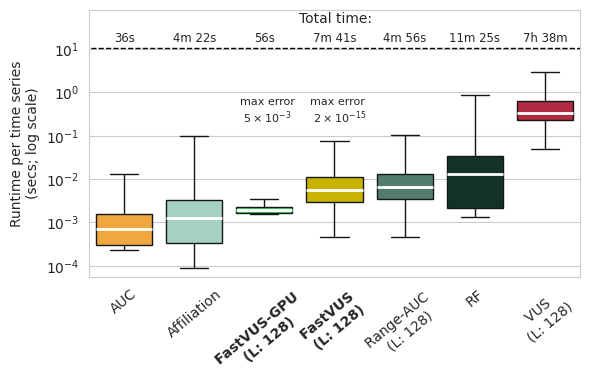

In [67]:
# What is the execution time difference
median_times = df.groupby('Metric')['Metric time'].median()
order = median_times.sort_values().index.to_list()

fig = plt.figure(figsize=(6, 4))

medianprops = dict(linestyle='-', linewidth=2, color='white')
meanprops = dict(
    marker='X',
    markerfacecolor='white',
    markeredgecolor='black',
    markersize=6
)

axis = sns.boxplot(
    y='Metric time',
    x='Metric',
    hue='Metric',
    data=df,
    showfliers=False,
    log_scale=True,
    showmeans=False,
    meanprops=meanprops,
    medianprops=medianprops,
    palette=color_palette,
    order=order,
    saturation=1,
)
axis.set_ylabel('Runtime per time series\n(secs; log scale)')
axis.set_xlabel('')
axis.tick_params(axis='x', rotation=40)
axis.grid(visible=False, axis='x')
axis.hlines(y=10.5, xmin=-1, xmax=7, linestyle='--', lw=1, color='k')
axis.set_xlim(-0.5, 6.5)
axis.set_ylim(0, 80)
axis.text(2.5, 40, 'Total time:')

for i, metric in enumerate(order):
    if my_vus_name in metric:
        max_err  = dif_df[metric].max()
        mean_err = dif_df[metric].mean()
        print(f'{metric} => max error: {max_err:.0e}, mean error: {mean_err:.0e}, median error: {dif_df[metric].median():.0e}')
        axis.annotate(
            f'max error\n ${_sci_latex(max_err)}$',#\nmean error\n   ${_sci_latex(mean_err)}$',
            xy=(i, 10),
            xytext=(i - .35, 0.2),
            fontsize=8,
        )
    total = df.loc[df['Metric'] == metric].groupby(['Time series', 'Detector'])['Metric time'].mean().sum()
    if total > 3600:
        h, m = divmod(int(total) // 60, 60)
        label = f'{h}h {m}m'
    elif total > 100:
        m, s = divmod(int(total), 60)
        label = f'{m}m {s}s'
    else:
        label = f'{total:.0f}s'
    axis.text(i, 25, label, ha='center', va='top', fontsize='small')
    print(f"{metric}: total time {label}")
        

# Highlight the 2nd and 3rd xtick_label in bold
xticklabels = axis.get_xticklabels()
for idx in range(len(axis.get_xticklabels())):
    if my_vus_name in xticklabels[idx].get_text():
        xticklabels[idx].set_fontweight('bold')
    if '(L:' in xticklabels[idx].get_text(): 
        new_text = xticklabels[idx].get_text().replace('(', '\n(')
        xticklabels[idx].set_text(new_text)
axis.set_xticks(axis.get_xticks())
axis.set_xticklabels([label.get_text() for label in xticklabels])

# # Remove borders around the boxes but keep whiskers and caps
# for j, patch in enumerate(axis.patches):
#     facecolor = patch.get_facecolor()
#     if all([x == 1 for x in facecolor]):
#         patch.set_facecolor((1, 1, 1, 0.0))  # alpha = 0.0
#         patch.set_edgecolor((0, 0, 0, 1.0))  # fully opaque border
#         patch.set_linewidth(1.5)

#         axis.lines[j * 6 + 4].set_color('black')    # 6 lines per box and usually the median is the 4th
#         axis.lines[j * 6 + 4].set_linewidth(1.5)
#     else:
#         patch.set_edgecolor(facecolor)
#         patch.set_linewidth(0.5)

finalize_plot(save_fig_path, 'exec_time_comparison_tsb')

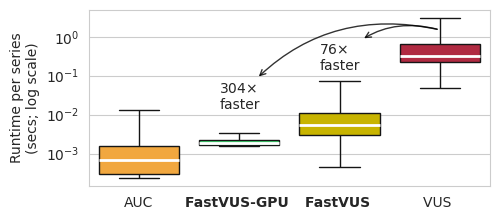

In [68]:
# What is the execution time difference
curr_df  = df[df['Metric'].isin(['AUC', f'{my_vus_name}-GPU (L: 128)', f'{my_vus_name} (L: 128)', 'VUS (L: 128)'])]
median_times = curr_df.groupby('Metric')['Metric time'].mean()
order = median_times.sort_values().index.to_list()

plt.figure(figsize=(5.1, 2.3))

axis = sns.boxplot(
    y='Metric time',
    x='Metric',
    hue='Metric',
    data=curr_df,
    showfliers=False,
    log_scale=True,
    showmeans=False,
    meanprops=meanprops,
    medianprops=medianprops,
    palette=color_palette,
    order=order,
    saturation=1,
)
axis.set_ylabel('Runtime per series\n(secs; log scale)')
axis.set_xlabel('')
axis.tick_params(axis='x', rotation=0)
axis.grid(visible=False, axis='x')

for i, metric in enumerate(order):
    if my_vus_name in metric:
        axis.annotate(
            f'{speed_up_dict[metric]:.0f}$\\times$\nfaster', 
            xy=(3, 1.5), 
            xytext=(i - 0.2, 0.07 if i == 1 else 0.09 + i*0.3),
            arrowprops=dict(arrowstyle="<-", connectionstyle="arc3,rad=-.3", color='k', alpha=0.8),
            # ha='center',
            va='top'
        )

# Highlight the 2nd and 3rd xtick_label in bold
xticklabels = axis.get_xticklabels()
for idx in range(len(axis.get_xticklabels())):
    if my_vus_name in xticklabels[idx].get_text():
        xticklabels[idx].set_fontweight('bold')
    if '(L:' in xticklabels[idx].get_text(): 
        new_text = xticklabels[idx].get_text().replace('(L: 128)', '')
        xticklabels[idx].set_text(new_text)
axis.set_xticks(axis.get_xticks())
axis.set_xticklabels([label.get_text() for label in xticklabels])

finalize_plot(save_fig_path, 'exec_time_comparison_tsb_small')

### Error boxplot

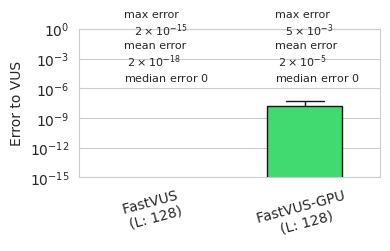

In [69]:
plt.figure(figsize=(4, 2.5))

axis = sns.boxplot(
    dif_df,
    showfliers=False, 
    fill=True, 
    flierprops={"marker": "o"},
    medianprops=medianprops,
    width=.5, 
    palette=color_palette, 
    saturation=1,
    # whis=[0, 100]
)
axis.set_ylabel('Error to VUS')
axis.set_xlabel('')
axis.tick_params(axis='x', rotation=15)
axis.grid(visible=False, axis='x')
axis.set_yscale('log')
axis.set_yticks([10**-x for x in range(0, 16)][::3])

for i, metric in enumerate(dif_df.columns):
    max_err  = dif_df[metric].max()
    mean_err = dif_df[metric].mean()
    median_err = dif_df[metric].median()
    axis.annotate(
        f'max error\n   ${_sci_latex(max_err)}$\nmean error\n ${_sci_latex(mean_err)}$\nmedian error ${_sci_latex(median_err)}$',
        (i - 0.2, 0.000005),
        fontsize=8,
    )

# Add newline character
xticklabels = axis.get_xticklabels()
for idx in range(len(axis.get_xticklabels())):
    if '(L:' in xticklabels[idx].get_text(): 
        new_text = xticklabels[idx].get_text().replace('(', '\n(')
        xticklabels[idx].set_text(new_text)
axis.set_xticks(axis.get_xticks())
axis.set_xticklabels([label.get_text() for label in xticklabels])

finalize_plot(save_fig_path, 'ffvus_error_analysis_tsb')

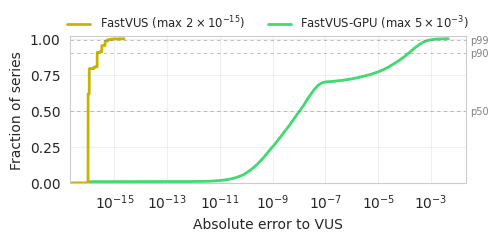

In [70]:
# ECDF(x) = fraction of series with |error| <= x.
# Exact-zero / sub-eps errors can't sit on a log axis, so floor them to a tiny
# value that reads as "exact to double precision".
eps_floor = 1e-16
abs_err = dif_df.abs().clip(lower=eps_floor)

plt.figure(figsize=(5, 2.5))
axis = sns.ecdfplot(data=abs_err, palette=color_palette, linewidth=2)
axis.set_xscale('log')
axis.set_xlabel('Absolute error to VUS')
axis.set_ylabel('Fraction of series')
axis.set_ylim(0, 1.02)
axis.grid(visible=True, axis='both', alpha=.3)

# percentile reference lines, labelled just outside the right edge
for q in (0.5, 0.9, 0.99):
    axis.axhline(q, color='gray', lw=.6, ls=(0, (4, 4)), alpha=.6)
    axis.text(1.01, q, f'p{int(q*100)}',
              transform=axis.get_yaxis_transform(), clip_on=False,
              va='center', ha='left', fontsize=7, color='gray')

sns.move_legend(
    axis, loc='lower center', bbox_to_anchor=(0.5, 0.96),
    ncol=len(dif_df.columns), title=None, frameon=False, fontsize='small',
)
for t in axis.get_legend().get_texts():
    m = t.get_text()
    t.set_text(f'{m.replace(" (L: 128)", "")} (max ${_sci_latex(dif_df[m].abs().max())}$)')

finalize_plot(save_fig_path, 'ffvus_error_analysis_tsb')

## Experiment 2: All metrics with default parameters on the synthetic datasets

In [71]:
curr_experiment_path = os.path.join(experiments_path, 'allmetrics_defparams_syn', 'results')
df = load_results(curr_experiment_path)    
df['Metric'] = df['Metric'].map(formal_names)
df.sample(3)

100%|██████████| 70/70 [00:00<00:00, 420.99it/s]


,Time series,Length,Number of anomalies,Anomalies average length,Metric,Metric value,Metric time,Slope size,Step,Global mask,...,Anomaly coordinates time,Safe mask time,Thresholds time,Score mask time,Position time,Slopes time,Existence time,Confusion matrix time,Precision recall curve time,Integral time
2334,syn_len_100000_n_300_avglen_10.npz,100000,290,10.172414,AUC,0.920612,0.011347,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
14,syn_len_100000_n_10_avglen_400.npz,100000,9,413.888889,Affiliation,0.863965,0.030946,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1535,syn_len_100000_n_10_avglen_1000.npz,100000,9,1039.777778,AUC,0.890535,0.011147,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Time series characteristics runtime analysis

In [72]:
length_analysis_df = df[df['Length'] != 100_000]
n_anomalies_analysis_df = df[np.logical_and(df['Time series'].str.contains('len_100000_'), df['Time series'].str.contains('_avglen_10.npz'))]
avg_anomaly_length_analysis_df = df[df['Time series'].str.contains('len_100000_n_10_')]

avg_anomaly_length_analysis_df.loc[:, 'Anomalies average length'] = avg_anomaly_length_analysis_df.apply(lambda row: int(row['Time series'].split('_')[-1].replace('.npz', '')), axis=1)
n_anomalies_analysis_df.loc[:, 'Number of anomalies'] = n_anomalies_analysis_df.apply(lambda row: int(row['Time series'].split('_')[-3]), axis=1)

analysis_dfs = [
    length_analysis_df, 
    n_anomalies_analysis_df, 
    avg_anomaly_length_analysis_df
]
attributes = ["Length", "Number of anomalies", "Anomalies average length"]

In [73]:
# n_anomalies_analysis_df[np.logical_and(n_anomalies_analysis_df['Metric'].str.contains('GPU'), n_anomalies_analysis_df['Anomalies average length'] >= 10.)]


/home/sylli/miniconda3/envs/ffvus/lib/python3.12/site-packages/matplotlib/scale.py:270: RuntimeWarning: overflow encountered in power
  return np.power(self.base, values)
/tmp/ipykernel_11453/693262018.py:2: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


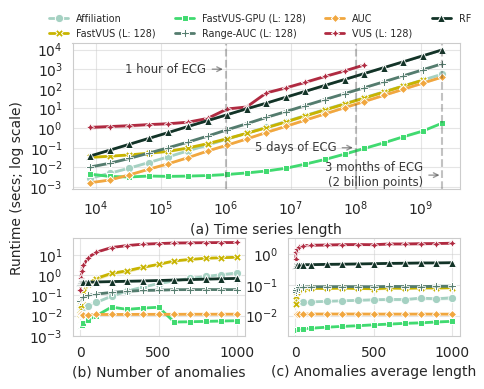

In [74]:
fig = plt.figure(figsize=(5, 3.8))
gs = GridSpec(2, 2, figure=fig, height_ratios=[3, 2], wspace=0.25, hspace=0.4)
attr_axis = {
    "Length": gs[0, :],
    "Number of anomalies": gs[1, 0],
    "Anomalies average length": gs[1, 1],
}
abc_numbered = {0: 'a', 1: 'b', 2: 'c'}

legend_axis = None
for i, attribute in enumerate(attributes):
    axis = fig.add_subplot(attr_axis[attribute])
    curr_df = analysis_dfs[i]

    sns.lineplot(
        x=attribute,
        y='Metric time',
        hue='Metric',
        data=curr_df,
        ax=axis,
        palette=color_palette,
        markers=True,
        style='Metric',
        dashes=False,
        linewidth=2,
        zorder=1,
        estimator=np.median
    )
    axis.set_yscale('log')
    axis.grid(axis='both', alpha=0.5)
    axis.set_xlabel(f"({abc_numbered[i]}) {attribute if attribute != 'Length' else "Time series length"}")
    axis.set_ylabel('')

    if attribute == "Length":
        axis.set_xscale('log', base=10)
    if i != 0:
        axis.get_legend().remove()
        if i == 1:
            axis.set_yticks([0.001, 0.01, 0.1, 1, 10])    
    else:
        legend_axis = axis

        axis.set_yticks([0.001, 0.01, 0.1, 1, 10, 100, 1000, 10000])

        # 1 million points (~1 hour of ECG)
        x_val = 1e6
        y_val = 1000
        curr_color = "#383838"
        axis.annotate("1 hour of ECG",
                    xy=(x_val, y_val), xytext=(x_val / 2, y_val),
                    ha='right', va='center', fontsize='small', color=curr_color,
                    arrowprops=dict(arrowstyle="->", color=curr_color, alpha=0.5))
        axis.axvline(x=x_val, ymin=0, ymax=20000, color=curr_color, linestyle='--', alpha=0.3)

        # 100 million points (~5 days of ECG)
        x_val = 1e8
        y_val = 0.1
        axis.annotate("5 days of ECG",
                    xy=(x_val, y_val), xytext=(x_val / 2, y_val),
                    ha='right', va='center', fontsize='small', color=curr_color,
                    arrowprops=dict(arrowstyle="->", color=curr_color, alpha=0.5))
        axis.axvline(x=x_val, ymin=0, ymax=20000, color=curr_color, linestyle='--', alpha=0.3)

        # 1 billion points (~3 months of ECG)
        x_val = 2**31
        y_val = 0.004
        axis.annotate("3 months of ECG\n(2 billion points)",
                    xy=(x_val, y_val), xytext=(x_val / 2, y_val),
                    ha='right', va='center', fontsize='small', color=curr_color,
                    arrowprops=dict(arrowstyle="->", color=curr_color, alpha=0.5))
        axis.axvline(x=x_val, ymin=0, ymax=20000, color=curr_color, linestyle='--', alpha=0.3)

fig.text(
    0, 0.5,
    "Runtime (secs; log scale)",
    va='center',
    rotation='vertical',
)

if legend_axis:
    handles, labels = legend_axis.get_legend_handles_labels()
    legend_axis.get_legend().remove()
    fig.legend(
        handles,
        labels,
        loc='upper center',
        bbox_to_anchor=(0.5, 0.98),
        ncol=4,#(len(labels)//2),
        # nrow=2,
        frameon=False,
        fontsize='x-small'
    )
finalize_plot(save_fig_path, 'exec_time_per_ts_char_syn')

### Computation step runtime analysis

In [81]:
rename_dict = {
    'Anomaly coordinates time': 'Anom.',
    'Safe mask time': 'Mask',
    'Thresholds time': 'Thresh.',
    'Score mask time': 'Scores',
    'Position time': 'Pos.',
    'Slopes time': 'Buffers',
    'Existence time': 'Existence',
    'Confusion matrix time': 'Conf. mat.',
    'Precision recall curve time': 'PR curve',
    'Integral time': 'Integral',
}
rename_dict = {k: f'({chr(i + 97)}) {v}' for i, (k, v) in enumerate(rename_dict.items())}

/tmp/ipykernel_69282/4223353290.py:30: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axis.legend()


ValueError: number sections must be larger than 0.

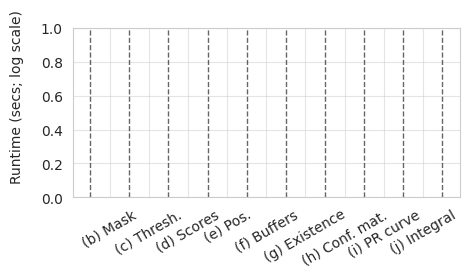

In [82]:
time_analysis_cols = [x for x in df.columns if 'time' in x and x != 'Metric time']
metrics = ['Fast-VUS (L: 128)', 'Fast-VUS-GPU (L: 128)']
curr_df = df[df['Metric'].isin(metrics)]

fig, axis = plt.subplots(1, 1, figsize=(5, 2.2))
for i, col in enumerate(time_analysis_cols):
    sns.boxplot(
        curr_df, 
        ax=axis, 
        x=i, 
        y=col, 
        log_scale=True, 
        legend=(i == 0), 
        hue='Metric',
        palette=color_palette, 
        showfliers=False,
        saturation=1
    )
    if i != 0:
        axis.set_xticks(np.arange(len(time_analysis_cols)), [rename_dict[x] for x in time_analysis_cols])
    else:
        axis.set_xticks(np.arange(len(time_analysis_cols)), [])

    axis.axvline(x=i+0.5, linestyle='--', color='k', lw=1, alpha=0.6)
axis.set_title('')
axis.set_ylabel('')
axis.set_xlabel('')
axis.tick_params(axis='x', rotation=30)
axis.grid(axis='both', alpha=0.5)
axis.legend()

fig.text(
    0, 0.57,
    "Runtime (secs; log scale)",
    va='center',
    rotation='vertical',
)

handles, labels = axis.get_legend_handles_labels()
axis.get_legend().remove()
fig.legend(
    handles,
    labels,
    loc='upper center',
    bbox_to_anchor=(0.5, 1.03),
    ncol=len(labels),
    frameon=False,
    fontsize='small'
)

finalize_plot(save_fig_path, 'per_part_runtime_syn')

## Experiment 3: VUS / Buffer & Step comparison / TSB

### Buffer comparison

In [83]:
curr_experiment_path = os.path.join(experiments_path, 'vus_buffer_comparison_tsb', 'results')
df = load_results(curr_experiment_path)    
df['Metric'] = df['Metric'].map(formal_names)
df.sample(3)

100%|██████████| 30/30 [00:00<00:00, 167.26it/s]


,Time series,Length,Number of anomalies,Anomalies average length,Slope size,Existence,Metric,Metric value,Metric time,Step,...,Anomaly coordinates time,Safe mask time,Thresholds time,Score mask time,Position time,Slopes time,Existence time,Confusion matrix time,Precision recall curve time,Integral time
36767,SMD/machine-1-6.test.csv@11.out,23688,30,123.6,512,True,VUS (L: 128),0.502900,12.099699,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7870,OPPORTUNITY/S2-ADL3.test.csv@94.out,33983,2,456.5,128,True,FastVUS-GPU (L: 128),0.214646,0.002871,1.0,...,0.000399,0.000367,0.000175,0.000036,0.000077,0.000216,0.000196,0.000488,0.000103,0.000042
1703,KDD21/121_UCR_Anomaly_ECG3_15000_16000_16100.out,29999,1,100.0,2,True,VUS (L: 128),0.756841,0.013197,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


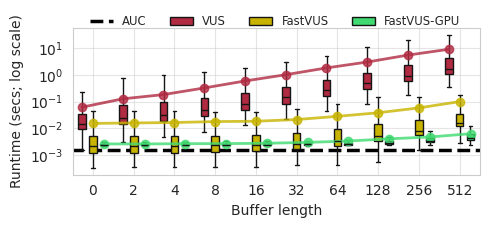

In [84]:
order = ['VUS (L: 128)', f'{my_vus_name} (L: 128)', f'{my_vus_name}-GPU (L: 128)']

fig, axis = plt.subplots(1, 1, figsize=(5, 2.2))

# First create the boxplot
axis.hlines(y=df_auc['Metric time'].mean(), xmin=-1, xmax=10, linestyle='--', lw=2.5, color='k', label='AUC')
sns.boxplot(
    ax=axis,
    y='Metric time', 
    x='Slope size', 
    hue='Metric', 
    data=df, 
    showfliers=False, 
    log_scale=True, 
    palette=color_palette, 
    saturation=1,
    gap=.3,
    hue_order=order
)


# Add lines connecting means for each metric
for i, metric in enumerate(order):
    means = df[df['Metric'] == metric].groupby('Slope size')['Metric time'].mean()
    axis.plot(np.arange(len(means)) + (i - 1) * 0.27, means, '-o', lw=2, label=f'{metric} mean', alpha=0.8, color=color_palette[metric])

plt.xlabel('Buffer length')
plt.ylabel('Runtime (secs; log scale)')
plt.grid(axis='both', alpha=0.5)
axis.set_xlim(-0.5, 9.5)

handles, labels = axis.get_legend_handles_labels()
labels = [label.replace(' (L: 128)', '').replace(' mean', '') for label in labels[:4]]
axis.get_legend().remove()
fig.legend(
    handles[:4],
    labels,
    loc='upper center',
    bbox_to_anchor=(0.56, 1.04),
    ncol=len(labels),
    frameon=False,
    fontsize='small'
)

finalize_plot(save_fig_path, 'exec_time_buffer_comparison')

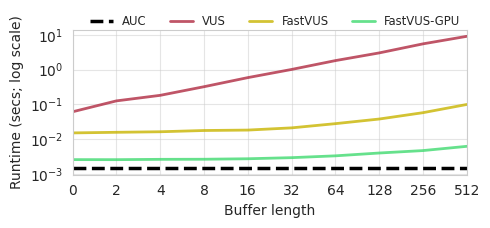

In [85]:
order = ['VUS (L: 128)', f'{my_vus_name} (L: 128)', f'{my_vus_name}-GPU (L: 128)']

fig, axis = plt.subplots(1, 1, figsize=(5, 2.2))

# AUC reference line
axis.axhline(y=df_auc['Metric time'].mean(), linestyle='--', lw=2.5, color='k', label='AUC')

# One line per metric
for metric in order:
    means = df[df['Metric'] == metric].groupby('Slope size')['Metric time'].mean()
    axis.plot(np.arange(len(means)), means, '-', lw=2, label=metric, alpha=0.8, color=color_palette[metric])

axis.set_yscale('log')
plt.xlabel('Buffer length')
plt.ylabel('Runtime (secs; log scale)')
plt.grid(axis='both', alpha=0.5)
axis.set_xlim(0, 9)
axis.set_xticks(np.arange(len(means)))
axis.set_xticklabels(means.index)

handles, labels = axis.get_legend_handles_labels()
labels = [label.replace(' (L: 128)', '') for label in labels]
fig.legend(
    handles,
    labels,
    loc='upper center',
    bbox_to_anchor=(0.56, 1.04),
    ncol=len(labels),
    frameon=False,
    fontsize='small'
)

finalize_plot(save_fig_path, 'exec_time_buffer_comparison')


### Step comparison

In [44]:
curr_experiment_path = os.path.join(experiments_path, 'vus_step_comparison_tsb', 'results')
df_step = load_results(curr_experiment_path)    
df_step['Metric'] = df_step['Metric'].map(formal_names)
df_step.sample(3)

100%|██████████| 20/20 [00:00<00:00, 76.35it/s]


,Time series,Length,Number of anomalies,Anomalies average length,Slope size,Step,Global mask,Slopes,Existence,Confusion matrix,...,Score mask time,Position time,Slopes time,Existence time,Confusion matrix time,Precision recall curve time,Integral time,Metric,Metric value,Metric time
37196,YAHOO/YahooA4Benchmark-TS18_data.out,1679,1,1.0,512,16,True,function,True,dynamic_plus,...,0.000033,0.000070,0.000194,0.000160,0.000293,0.000088,0.000035,Fast-VUS-GPU (L: 128),0.771398,0.002352
24925,OPPORTUNITY/S3-ADL2.test.csv@53.out,27456,2,709.5,512,128,True,function,True,dynamic_plus,...,0.000033,0.000068,0.000190,0.000161,0.000269,0.000089,0.000035,Fast-VUS-GPU (L: 128),0.197978,0.002397
18669,KDD21/015_UCR_Anomaly_DISTORTEDECG4_5000_16800...,199999,1,300.0,512,64,True,precomputed,optimized,dynamic_plus,...,0.001655,0.000109,0.000058,0.000099,0.000331,0.000040,0.000029,Fast-VUS (L: 128),0.085705,0.008565


In [45]:
df_vus_512 = df[np.logical_and(df['Metric'] == 'VUS (L: 128)', df['Slope size'] == 512)]

In [46]:
df_vus_512_control = df_vus_512.set_index('Time series')['Metric value']

df_step['Error'] = df_step.apply(lambda row: row['Metric value'] - df_vus_512_control.loc[row['Time series']], axis=1)
df_step.sample(3)

,Time series,Length,Number of anomalies,Anomalies average length,Slope size,Step,Global mask,Slopes,Existence,Confusion matrix,...,Position time,Slopes time,Existence time,Confusion matrix time,Precision recall curve time,Integral time,Metric,Metric value,Metric time,Error
33574,SVDB/850.test.csv@2.out,230399,2,391.0,512,16,True,precomputed,optimized,dynamic_plus,...,0.000224,0.000207,0.000182,0.001086,0.000073,0.000045,Fast-VUS (L: 128),0.030859,0.020956,-0.000105
35162,YAHOO/Yahoo_A2synthetic_80_data.out,1420,3,3.0,512,8,True,precomputed,optimized,dynamic_plus,...,0.000124,0.000378,0.000432,0.001231,0.000117,0.000053,Fast-VUS (L: 128),0.298235,0.002665,0.001326
27341,SMD/machine-2-3.test.csv@2.out,23688,10,26.9,512,512,True,precomputed,optimized,dynamic_plus,...,0.000638,0.000114,0.000296,0.002130,0.000034,0.000024,Fast-VUS (L: 128),0.174869,0.004400,-0.005136


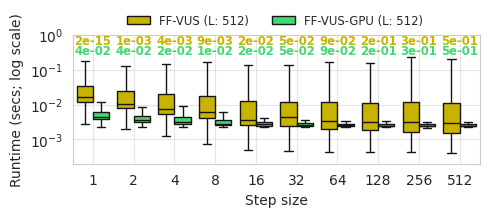

In [47]:
fig, axis = plt.subplots(1, 1, figsize=(5, 2.1))
# plt.hlines(df_vus_512['Metric time'].mean(), xmin=-1, xmax=512, lw=2.5, color=color_palette['VUS (L: 128)'], linestyle='--', label='VUS (L: 512)')
sns.boxplot(
    y='Metric time', 
    x='Step', 
    data=df_step, 
    showfliers=False, 
    log_scale=True,
    hue='Metric',
    palette=color_palette,
    saturation=1,
    ax=axis
)
axis.set_xlabel('Step size')
axis.set_ylabel('Runtime (secs; log scale)')
axis.tick_params(axis='x', labelrotation=0)
axis.grid(axis='both', alpha=0.5)
axis.set_ylim(0.0002, 1)

# annotate error info above each Step box
steps = sorted(df_step['Step'].dropna().unique())
for i, s in enumerate(steps):
    # errs = df_step.loc[df_step['Step'] == s][['Metric', 'Error']]
    # print(errs)
    
    for j, metric in enumerate(metrics[::-1]):
        axis.text(i, 
            .23 + j*0.2, 
            f'{df_step[np.logical_and(df_step['Metric'] == metric, df_step['Step'] == s)]['Error'].abs().max():.0e}', 
            ha='center', 
            va='bottom', 
            fontsize='small',
            color=color_palette[metric],
            weight='bold',
            # bbox=dict(boxstyle="round,pad=0.3", fc="white", alpha=0.8)
        )

handles, labels = axis.get_legend_handles_labels()
labels = [label.replace(' (L: 128)', ' (L: 512)') for label in labels]
axis.get_legend().remove()
fig.legend(
    handles,
    labels,
    loc='upper center',
    bbox_to_anchor=(0.56, 1.04),
    ncol=len(labels),
    frameon=False,
    fontsize='small'
)

finalize_plot(save_fig_path, 'step_comparison')

/home/sylli/anaconda3/envs/ffvus/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:4596: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = b - a


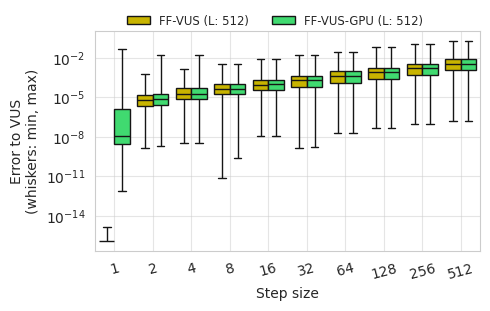

In [48]:
fig, axis = plt.subplots(1, 1, figsize=(5, 3))    
sns.boxplot(
    y='Error', 
    x='Step', 
    data=df_step, 
    showfliers=False, 
    log_scale=True,
    hue='Metric',
    palette=color_palette,
    saturation=1,
    ax=axis,
    whis=[0, 100]
)
axis.set_xlabel('Step size')
axis.set_ylabel('Error to VUS\n(whiskers: min, max)')
axis.tick_params(axis='x', labelrotation=15)
# axis.set_yticks([10**i for i in range(-3, 4)])
axis.grid(axis='both', alpha=0.5)

handles, labels = axis.get_legend_handles_labels()
labels = [label.replace(' (L: 128)', ' (L: 512)') for label in labels]
axis.get_legend().remove()
fig.legend(
    handles,
    labels,
    loc='upper center',
    bbox_to_anchor=(0.56, 1.04),
    ncol=len(labels),
    frameon=False,
    fontsize='small'
)

finalize_plot(save_fig_path, 'error_step_comparison')

### Step rank evaluation

In [8]:
from scipy.stats import spearmanr, kendalltau

curr_experiment_path = os.path.join(experiments_path, 'compare_rank', 'results')
df = load_results(curr_experiment_path)
df = df.drop('index', axis=1)
# df['Metric'] = df['Metric'].map(formal_names)
df.sample(3)

100%|██████████| 20/20 [00:00<00:00, 49.36it/s]


,Time series,Metric,Step,Detector,Score,Runtime
245190,ECG/MBA_ECG14046_data_40.out,Fast-VUS,64.0,AE,0.411260,0.370909
361286,YAHOO/Yahoo_A1real_44_data.out,Fast-VUS,4.0,LSTM,0.760317,0.003707
205822,KDD21/221_UCR_Anomaly_STAFFIIIDatabase_45616_1...,Fast-VUS-GPU,1.0,MP,0.009718,0.005499


In [9]:
total_runtimes = df[df['Step'] == 1].groupby('Metric')['Runtime'].sum()

for metric, secs in total_runtimes.items():
    hrs = int(secs // 3600)
    mins = int((secs % 3600) // 60)
    print(f"{metric}: {hrs}h {mins}m")

Fast-VUS: 0h 38m
Fast-VUS-GPU: 0h 2m
VUS: 61h 33m


In [10]:
vus_df = df[df['Metric'] == 'VUS']
common_ts = vus_df['Time series'].unique()
df = df[np.logical_and(df['Time series'].isin(common_ts), df['Metric'] != 'VUS')]
df

,Time series,Metric,Step,Detector,Score,Runtime
72,Daphnet/S03R03E4.test.csv@3.out,Fast-VUS-GPU,1.0,AE,0.051531,0.006486
73,Daphnet/S03R03E4.test.csv@3.out,Fast-VUS-GPU,2.0,AE,0.051552,0.002911
74,Daphnet/S03R03E4.test.csv@3.out,Fast-VUS-GPU,4.0,AE,0.051585,0.002619
75,Daphnet/S03R03E4.test.csv@3.out,Fast-VUS-GPU,8.0,AE,0.051647,0.002504
76,Daphnet/S03R03E4.test.csv@3.out,Fast-VUS-GPU,16.0,AE,0.051764,0.002449
...,...,...,...,...,...,...
462019,KDD21/190_UCR_Anomaly_resperation4_70000_12843...,Fast-VUS,32.0,POLY,0.000642,0.020471
462020,KDD21/190_UCR_Anomaly_resperation4_70000_12843...,Fast-VUS,64.0,POLY,0.000748,0.020185
462021,KDD21/190_UCR_Anomaly_resperation4_70000_12843...,Fast-VUS,128.0,POLY,0.000991,0.020148
462022,KDD21/190_UCR_Anomaly_resperation4_70000_12843...,Fast-VUS,256.0,POLY,0.001384,0.019708


In [11]:
step_rank_results = []
vus_ts_unique = vus_df['Time series'].unique()
metrics_unique = df['Metric'].unique()
steps_unique = df['Step'].unique()

# Pre-index dataframes for faster lookup
vus_grouped = vus_df.set_index(['Time series', 'Detector'])['Score']
df_grouped = df.set_index(['Time series', 'Metric', 'Step', 'Detector'])['Score']

for ts in tqdm(vus_ts_unique):
    curr_vus = vus_grouped.loc[ts].sort_index()
    curr_vus_rank = curr_vus.rank(method='average')
    curr_vus_rank_values = curr_vus_rank.values

    for metric in metrics_unique:
        for step in steps_unique:
            try:
                curr_ff_step = df_grouped.loc[(ts, metric, step)].sort_index()
            except KeyError:
                continue
            curr_ff_rank = curr_ff_step.rank(method='average')
            curr_ff_rank_values = curr_ff_rank.values

            spear = spearmanr(curr_vus_rank_values, curr_ff_rank_values).correlation
            kend = kendalltau(curr_vus_rank_values, curr_ff_rank_values).correlation
            mean_diff = np.mean(np.abs(curr_vus_rank_values - curr_ff_rank_values))
            flips = np.mean(np.sign(curr_vus_rank_values[:, None] - curr_vus_rank_values[None, :]) !=
                    np.sign(curr_ff_rank_values[:, None] - curr_ff_rank_values[None, :]))

            step_rank_results.append({
                'Time series': ts,
                'Metric': metric,
                'Step': step,
                'Spearman': spear,
                'Kendall': kend,
                'Mean rank diff.': mean_diff,
                'Order flips': flips
            })
df_rank_results = pd.DataFrame(step_rank_results)
df_rank_results

  0%|          | 0/1884 [00:00<?, ?it/s]/tmp/ipykernel_77306/2449298812.py:18: PerformanceWarning: indexing past lexsort depth may impact performance.
  curr_ff_step = df_grouped.loc[(ts, metric, step)].sort_index()
100%|██████████| 1884/1884 [00:34<00:00, 55.36it/s]


,Time series,Metric,Step,Spearman,Kendall,Mean rank diff.,Order flips
0,Genesis/genesis-anomalies.test.csv@17.out,Fast-VUS-GPU,1.0,1.000000,1.000000,0.000000,0.000000
1,Genesis/genesis-anomalies.test.csv@17.out,Fast-VUS-GPU,2.0,1.000000,1.000000,0.000000,0.000000
2,Genesis/genesis-anomalies.test.csv@17.out,Fast-VUS-GPU,4.0,1.000000,1.000000,0.000000,0.000000
3,Genesis/genesis-anomalies.test.csv@17.out,Fast-VUS-GPU,8.0,1.000000,1.000000,0.000000,0.000000
4,Genesis/genesis-anomalies.test.csv@17.out,Fast-VUS-GPU,16.0,1.000000,1.000000,0.000000,0.000000
...,...,...,...,...,...,...,...
37675,Dodgers/101-freeway-traffic.test.out,Fast-VUS,32.0,1.000000,1.000000,0.000000,0.000000
37676,Dodgers/101-freeway-traffic.test.out,Fast-VUS,64.0,1.000000,1.000000,0.000000,0.000000
37677,Dodgers/101-freeway-traffic.test.out,Fast-VUS,128.0,0.993007,0.969697,0.166667,0.013889
37678,Dodgers/101-freeway-traffic.test.out,Fast-VUS,256.0,0.986014,0.939394,0.333333,0.027778


In [63]:
df_rank_results.groupby(['Metric', 'Step'])[['Spearman', 'Kendall', 'Mean rank diff.', 'Order flips']].mean()

Spearman   Kendall  Mean rank diff.  Order flips
Metric     Step                                                   
Fast-VUS     1.0    1.000000  1.000000         0.000000     0.000000
           2.0    0.999918  0.999643         0.001946     0.000162
           4.0    0.999833  0.999276         0.003981     0.000332
           8.0    0.999457  0.997820         0.011943     0.000995
           16.0   0.998563  0.995084         0.026539     0.002248
           32.0   0.996625  0.989386         0.056352     0.004858
           64.0   0.992245  0.978672         0.111200     0.009753
           128.0  0.983502  0.959482         0.204264     0.018526
           256.0  0.970727  0.931570         0.339968     0.031287
           512.0  0.946804  0.887652         0.546576     0.051383
Fast-VUS-GPU 1.0    0.997317  0.992363         0.039544     0.003553
           2.0    0.998907  0.996104         0.021364     0.001887
           4.0    0.999178  0.996915         0.016720     0.001445
           8.0    0.999072  0.996472         0.019285     0.001666
           16.0   0.998469  0.994793         0.028397     0.002462
           32.0   0.996541  0.989212         0.057590     0.005020
           64.0   0.992196  0.978586         0.111952     0.009871
           128.0  0.983427  0.959357         0.205547     0.018754
           256.0  0.970663  0.931463         0.340941     0.031479
           512.0  0.946736  0.887528         0.547726     0.051589

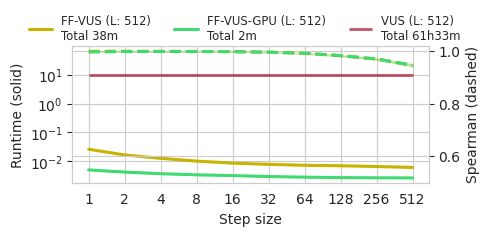

In [82]:
fig, ax1 = plt.subplots(figsize=(5, 2.1))

steps = [2**i for i in range(10)]
ax1.set_xscale('log', base=2)
ax1.set_xticks(steps)
ax1.get_xaxis().set_major_formatter(plt.ScalarFormatter())

ax1.set_yscale('log')
runtime_lines = sns.lineplot(
    data=df,
    x='Step', y='Runtime', hue='Metric',
    palette=color_palette, ax=ax1, lw=2.2
)
ax1.set_ylabel("Runtime (solid)")
ax1.set_xlabel("Step size")

vus_mean = vus_df['Runtime'].mean()
ax1.hlines(y=vus_mean, xmin=1, xmax=512, lw=2, ls='solid', color=color_palette['VUS (L: 128)'], label='VUS', alpha=0.8)

ax1.set_yticks([10**(x) for x in [-3, -2, -1, 0, 1]])
handles1, labels1 = ax1.get_legend_handles_labels()
ax1.legend().remove()
ax1.set_ylim(0.001, 50)

ax2 = ax1.twinx()
spearman_lines = sns.lineplot(
    data=df_rank_results,
    x='Step', y='Spearman', hue='Metric',
    palette=color_palette, ax=ax2,
    linestyle='--', lw=2.2
)
ax2.set_ylabel("Spearman (dashed)")
ax2.legend().remove()

# Adjust y-axis limits to better show the differences
ax1.set_ylim(0.0018, 100)
ax2.set_ylim(0.5, 1.02)

fig.legend(
    handles1,
    [x + ' (L: 512)\nTotal' + (f' {int(secs // 3600)}h' if int(secs // 3600) > 0 else ' ') + f'{int((secs % 3600) // 60)}m' for x, (metric, secs) in zip(labels1, total_runtimes.items())],
    loc='upper center',
    bbox_to_anchor=(0.5, 1.13),
    ncol=3,
    frameon=False,
    fontsize='small'
)

finalize_plot(save_fig_path, 'step_rank_comparison')

### Reviewer Q10: Worst-case error analysis for the step parameter

In [12]:
import sys
sys.path.insert(0, os.path.join('..'))

# ── 1. Load step comparison results ──────────────────────────────────────────
curr_experiment_path = os.path.join(experiments_path, 'vus_step_comparison_tsb', 'results')
step_df = load_results(curr_experiment_path)

# Separate CPU (Fast-VUS) and GPU (Fast-VUS-GPU) results based on filename / Metric column
step_df['Backend'] = step_df['Metric'].apply(lambda x: 'GPU' if 'GPU' in str(x) else 'CPU')
print(f"Loaded {len(step_df)} rows, backends: {step_df['Backend'].unique()}")
print(f"Steps: {sorted(step_df['Step'].unique())}")
print(f"Time series: {step_df['Time series'].nunique()}")
step_df.sample(3)

100%|██████████| 20/20 [00:00<00:00, 214.41it/s]

Loaded 37740 rows, backends: ['CPU' 'GPU']
Steps: [np.int64(1), np.int64(2), np.int64(4), np.int64(8), np.int64(16), np.int64(32), np.int64(64), np.int64(128), np.int64(256), np.int64(512)]
Time series: 1887


,Time series,Length,Number of anomalies,Anomalies average length,Slope size,Step,Global mask,Slopes,Existence,Confusion matrix,...,Position time,Slopes time,Existence time,Confusion matrix time,Precision recall curve time,Integral time,Metric,Metric value,Metric time,Backend
28609,OPPORTUNITY/S2-ADL3.test.csv@55.out,33983,2,456.5,512,4,True,precomputed,optimized,dynamic_plus,...,0.000225,0.000671,0.000210,0.001743,0.000082,0.000059,Fast-VUS,0.185729,0.006297,CPU
18052,YAHOO/YahooA3Benchmark-TS22_data.out,1679,4,1.0,512,1,True,function,True,dynamic_plus,...,0.000069,0.000206,0.000164,0.001550,0.000093,0.000044,Fast-VUS-GPU,0.970734,0.003638,GPU
25676,YAHOO/Yahoo_A2synthetic_71_data.out,1420,3,3.0,512,64,True,function,True,dynamic_plus,...,0.000068,0.000192,0.000168,0.000267,0.000088,0.000035,Fast-VUS-GPU,0.484607,0.002323,GPU


In [13]:
# ── 2. Compute per-series absolute error vs step=1 baseline ──────────────────
error_rows = []

for backend in ['CPU', 'GPU']:
    bdf = step_df[step_df['Backend'] == backend]
    
    # Baseline: step=1
    base = bdf[bdf['Step'] == 1].set_index('Time series')['Metric value']
    
    for step_val in sorted(bdf['Step'].unique()):
        if step_val == 1:
            continue
        curr = bdf[bdf['Step'] == step_val].set_index('Time series')['Metric value']
        common = base.index.intersection(curr.index)
        
        abs_err = (base.loc[common] - curr.loc[common]).abs()
        rel_err = abs_err / base.loc[common].replace(0, np.nan)
        
        for ts in common:
            error_rows.append({
                'Backend': backend,
                'Step': step_val,
                'Time series': ts,
                'Baseline value': base.loc[ts],
                'Approx value': curr.loc[ts],
                'Abs error': abs_err.loc[ts],
                'Rel error (%)': rel_err.loc[ts] * 100,
            })

err_df = pd.DataFrame(error_rows)

# ── 3. Summary statistics per step ──────────────────────────────────────────
summary = err_df.groupby(['Backend', 'Step']).agg(
    Mean_abs_err=('Abs error', 'mean'),
    Median_abs_err=('Abs error', 'median'),
    Max_abs_err=('Abs error', 'max'),
    Std_abs_err=('Abs error', 'std'),
    Mean_rel_err=('Rel error (%)', 'mean'),
    Max_rel_err=('Rel error (%)', 'max'),
    N=('Abs error', 'count'),
).reset_index()

print("=" * 90)
print("ERROR SUMMARY: |VUS(step=1) - VUS(step=s)| per step value")
print("=" * 90)
for backend in ['CPU', 'GPU']:
    print(f"\n{'─'*40} {backend} {'─'*40}")
    s = summary[summary['Backend'] == backend].sort_values('Step')
    for _, row in s.iterrows():
        print(f"  Step={int(row['Step']):>3d}  |  "
              f"Mean: {row['Mean_abs_err']:.6f}  "
              f"Median: {row['Median_abs_err']:.6f}  "
              f"Max: {row['Max_abs_err']:.6f}  "
              f"Mean rel: {row['Mean_rel_err']:.2f}%  "
              f"Max rel: {row['Max_rel_err']:.2f}%")

ERROR SUMMARY: |VUS(step=1) - VUS(step=s)| per step value

──────────────────────────────────────── CPU ────────────────────────────────────────
  Step=  2  |  Mean: 0.000175  Median: 0.000024  Max: 0.001289  Mean rel: 0.03%  Max rel: 0.76%
  Step=  4  |  Mean: 0.000523  Median: 0.000073  Max: 0.003599  Mean rel: 0.09%  Max rel: 3.18%
  Step=  8  |  Mean: 0.001293  Median: 0.000173  Max: 0.009286  Mean rel: 0.22%  Max rel: 10.53%
  Step= 16  |  Mean: 0.002944  Median: 0.000379  Max: 0.020216  Mean rel: 0.49%  Max rel: 9.05%
  Step= 32  |  Mean: 0.006885  Median: 0.000779  Max: 0.045666  Mean rel: 1.10%  Max rel: 7.20%
  Step= 64  |  Mean: 0.014718  Median: 0.001574  Max: 0.094633  Mean rel: 2.37%  Max rel: 66.67%
  Step=128  |  Mean: 0.029241  Median: 0.003191  Max: 0.178969  Mean rel: 4.75%  Max rel: 159.43%
  Step=256  |  Mean: 0.053080  Median: 0.006877  Max: 0.307565  Mean rel: 8.91%  Max rel: 298.30%
  Step=512  |  Mean: 0.086233  Median: 0.012223  Max: 0.470205  Mean rel: 15.04% 

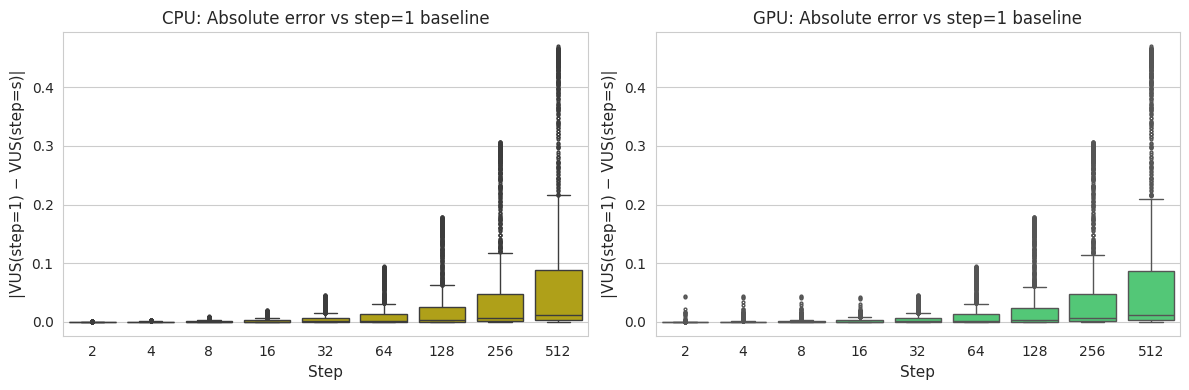

In [14]:
# ── 4. Plot: Error distribution across steps ────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=False)

for i, backend in enumerate(['CPU', 'GPU']):
    ax = axes[i]
    bdf = err_df[err_df['Backend'] == backend]
    
    sns.boxplot(
        data=bdf, x='Step', y='Abs error',
        order=sorted(bdf['Step'].unique()),
        color=color_palette.get('Fast-VUS' if backend == 'CPU' else 'Fast-VUS-GPU', '#999'),
        fliersize=2, ax=ax
    )
    ax.set_title(f'{backend}: Absolute error vs step=1 baseline', fontsize=12)
    ax.set_xlabel('Step', fontsize=11)
    ax.set_ylabel('|VUS(step=1) − VUS(step=s)|', fontsize=11)
    ax.tick_params(labelsize=10)

plt.tight_layout()
plt.show()

In [15]:
# ── 5. Identify worst-case time series per step and backend ──────────────────
worst_cases = err_df.loc[err_df.groupby(['Backend', 'Step'])['Abs error'].idxmax()]
worst_cases = worst_cases.sort_values(['Backend', 'Step'])

print("WORST-CASE TIME SERIES PER STEP")
print("=" * 110)
for _, row in worst_cases.iterrows():
    ts_short = row['Time series'].split('/')[-1] if '/' in row['Time series'] else row['Time series']
    print(f"  {row['Backend']:>3s} Step={int(row['Step']):>3d}  |  "
          f"Abs err: {row['Abs error']:.6f}  "
          f"Rel err: {row['Rel error (%)']:.2f}%  |  "
          f"Baseline: {row['Baseline value']:.6f}  "
          f"Approx: {row['Approx value']:.6f}  |  "
          f"{ts_short}")

WORST-CASE TIME SERIES PER STEP
  CPU Step=  2  |  Abs err: 0.001289  Rel err: 0.13%  |  Baseline: 0.973919  Approx: 0.972630  |  YahooA3Benchmark-TS66_data.out
  CPU Step=  4  |  Abs err: 0.003599  Rel err: 0.36%  |  Baseline: 0.986503  Approx: 0.982904  |  YahooA3Benchmark-TS36_data.out
  CPU Step=  8  |  Abs err: 0.009286  Rel err: 0.96%  |  Baseline: 0.968447  Approx: 0.959161  |  YahooA3Benchmark-TS5_data.out
  CPU Step= 16  |  Abs err: 0.020216  Rel err: 2.05%  |  Baseline: 0.986503  Approx: 0.966287  |  YahooA3Benchmark-TS36_data.out
  CPU Step= 32  |  Abs err: 0.045666  Rel err: 4.63%  |  Baseline: 0.986503  Approx: 0.940837  |  YahooA3Benchmark-TS36_data.out
  CPU Step= 64  |  Abs err: 0.094633  Rel err: 9.64%  |  Baseline: 0.981945  Approx: 0.887311  |  YahooA3Benchmark-TS38_data.out
  CPU Step=128  |  Abs err: 0.178969  Rel err: 18.23%  |  Baseline: 0.981945  Approx: 0.802975  |  YahooA3Benchmark-TS38_data.out
  CPU Step=256  |  Abs err: 0.307565  Rel err: 31.47%  |  Baselin

In [16]:
# ── 6. Deep-dive: Worst-case time series for CPU at key step values ──────────
# Load data so we can visualize the actual time series
from utils.dataloader import Dataloader
from utils.scoreloader import Scoreloader

dataloader = Dataloader(raw_data_path='../data/raw')
scoreloader = Scoreloader('../data/scores')

# Pick worst-case CPU series for step=2 (smallest step, "unlucky" scenario) and the biggest step
cpu_worst = worst_cases[worst_cases['Backend'] == 'CPU']
gpu_worst = worst_cases[worst_cases['Backend'] == 'GPU']

# Overall worst case across all steps, for both backends
overall_worst_cpu = cpu_worst.loc[cpu_worst['Abs error'].idxmax()]
overall_worst_gpu = gpu_worst.loc[gpu_worst['Abs error'].idxmax()]

print(f"Overall worst-case CPU: {overall_worst_cpu['Time series']}  "
      f"(step={int(overall_worst_cpu['Step'])}, abs_err={overall_worst_cpu['Abs error']:.6f})")
print(f"Overall worst-case GPU: {overall_worst_gpu['Time series']}  "
      f"(step={int(overall_worst_gpu['Step'])}, abs_err={overall_worst_gpu['Abs error']:.6f})")

Overall worst-case CPU: YAHOO/YahooA4Benchmark-TS1_data.out  (step=512, abs_err=0.470205)
Overall worst-case GPU: YAHOO/YahooA4Benchmark-TS1_data.out  (step=512, abs_err=0.470238)


In [17]:
# ── 7. Visualize overall worst-case time series for each backend ─────────────
from vus.vus_numpy import VUSNumpy

def load_single_ts(ts_name, dataloader, scoreloader):
    """Load a single time series by its name (e.g. 'ECG/chfdb_chf15_45590.out')."""
    dataset, fname = ts_name.split('/')
    path = os.path.join(dataloader.raw_data_path, dataset, fname)
    data = pd.read_csv(path, header=None).to_numpy()
    ts_values, label = data[:, 0], data[:, 1].astype(int)
    
    # Load score (first detector)
    detectors = scoreloader.get_detector_names()
    score_path = os.path.join(scoreloader.scores_path, dataset, detectors[0], 'score', fname)
    score = pd.read_csv(score_path, header=None).to_numpy().flatten()
    
    return ts_values, label, score

def plot_worst_case_ts(ts_name, backend, err_df_backend, dataloader, scoreloader):
    """Plot a single worst-case time series: its data, label, score, 
    and VUS values across all step values."""
    ts_values, label, score = load_single_ts(ts_name, dataloader, scoreloader)
    
    # Get all step errors for this time series
    ts_errs = err_df_backend[err_df_backend['Time series'] == ts_name].sort_values('Step')
    
    # Also get the baseline value
    baseline_val = ts_errs['Baseline value'].iloc[0]
    
    fig = plt.figure(figsize=(14, 8))
    gs = GridSpec(3, 2, figure=fig, width_ratios=[2, 1], hspace=0.35, wspace=0.3)
    
    # ── Left column: Time series + label + score ──
    ax_ts = fig.add_subplot(gs[0, 0])
    ax_ts.plot(ts_values, linewidth=0.5, color='steelblue', alpha=0.8)
    # Shade anomaly regions
    anomaly_starts = np.where(np.diff(np.concatenate(([0], label))) == 1)[0]
    anomaly_ends = np.where(np.diff(np.concatenate((label, [0]))) == -1)[0]
    for s, e in zip(anomaly_starts, anomaly_ends):
        ax_ts.axvspan(s, e, alpha=0.3, color='red')
    ax_ts.set_title(f'Time series: {ts_name}', fontsize=11, fontweight='bold')
    ax_ts.set_ylabel('Value')
    ax_ts.set_xlim(0, len(ts_values))
    
    ax_label = fig.add_subplot(gs[1, 0], sharex=ax_ts)
    ax_label.fill_between(range(len(label)), label, alpha=0.5, color='red', label='Label')
    ax_label.set_ylabel('Label')
    ax_label.set_ylim(-0.1, 1.3)
    ax_label.set_xlim(0, len(ts_values))
    
    ax_score = fig.add_subplot(gs[2, 0], sharex=ax_ts)
    ax_score.plot(score, linewidth=0.5, color='darkorange')
    for s, e in zip(anomaly_starts, anomaly_ends):
        ax_score.axvspan(s, e, alpha=0.15, color='red')
    ax_score.set_ylabel('Score')
    ax_score.set_xlabel('Time')
    ax_score.set_xlim(0, len(ts_values))
    
    # ── Right column: VUS value and abs error vs step ──
    ax_vus = fig.add_subplot(gs[0, 1])
    steps = ts_errs['Step'].values
    approx_vals = ts_errs['Approx value'].values
    ax_vus.axhline(baseline_val, color='black', linestyle='--', linewidth=1.5, label=f'step=1: {baseline_val:.6f}')
    ax_vus.plot(steps, approx_vals, 'o-', color=color_palette.get('Fast-VUS' if backend == 'CPU' else 'Fast-VUS-GPU'), 
                markersize=5, linewidth=1.5, label='Approx')
    ax_vus.set_xscale('log', base=2)
    ax_vus.set_xlabel('Step')
    ax_vus.set_ylabel('VUS-PR value')
    ax_vus.set_title(f'{backend}: VUS-PR vs step', fontsize=11)
    ax_vus.legend(fontsize=9)
    
    ax_err = fig.add_subplot(gs[1, 1])
    abs_errs = ts_errs['Abs error'].values
    ax_err.plot(steps, abs_errs, 's-', color='firebrick', markersize=5, linewidth=1.5)
    ax_err.set_xscale('log', base=2)
    ax_err.set_xlabel('Step')
    ax_err.set_ylabel('|Error|')
    ax_err.set_title('Absolute error', fontsize=11)
    
    ax_rel = fig.add_subplot(gs[2, 1])
    rel_errs = ts_errs['Rel error (%)'].values
    ax_rel.plot(steps, rel_errs, 's-', color='darkorchid', markersize=5, linewidth=1.5)
    ax_rel.set_xscale('log', base=2)
    ax_rel.set_xlabel('Step')
    ax_rel.set_ylabel('Relative error (%)')
    ax_rel.set_title('Relative error', fontsize=11)
    
    # Info text
    n_anomalies = len(anomaly_starts)
    fig.suptitle(
        f"Worst-case analysis — {backend}  |  Length: {len(ts_values):,}  |  "
        f"#Anomalies: {n_anomalies}  |  Max abs error: {abs_errs.max():.6f}",
        fontsize=12, fontweight='bold', y=1.02
    )
    plt.show()

# Plot worst-case for CPU
print("═" * 80)
print("WORST-CASE CPU TIME SERIES (across all step values)")
print("═" * 80)
plot_worst_case_ts(overall_worst_cpu['Time series'], 'CPU', 
                   err_df[err_df['Backend'] == 'CPU'], dataloader, scoreloader)

# Plot worst-case for GPU
print("\n" + "═" * 80)
print("WORST-CASE GPU TIME SERIES (across all step values)")
print("═" * 80)
plot_worst_case_ts(overall_worst_gpu['Time series'], 'GPU', 
                   err_df[err_df['Backend'] == 'GPU'], dataloader, scoreloader)

════════════════════════════════════════════════════════════════════════════════
WORST-CASE CPU TIME SERIES (across all step values)
════════════════════════════════════════════════════════════════════════════════


FileNotFoundError: [Errno 2] No such file or directory: '../data/raw/YAHOO/YahooA4Benchmark-TS1_data.out'

In [18]:
# ── 8. Recompute VUS for worst-case series with step=1 vs worst step ─────────
# This verifies the error and shows the intermediate existence/confusion matrices

def compare_step_detailed(ts_name, step_vals, dataloader, scoreloader, slope_size=512):
    """Recompute VUS for a given time series at multiple step values and display results."""
    ts_values, label, score = load_single_ts(ts_name, dataloader, scoreloader)
    
    results = {}
    for s in step_vals:
        vus = VUSNumpy(slope_size=slope_size, step=s, global_mask=True, 
                       slopes='precomputed', existence='optimized', conf_matrix='dynamic_plus')
        (metric_val, _), _ = vus.compute(label, score)
        results[s] = metric_val
    
    print(f"\n  Time series: {ts_name}")
    print(f"  Length: {len(label):,}  |  #Anomalies: {np.sum(np.diff(np.concatenate(([0], label))) == 1)}")
    print(f"  {'Step':>6s}  {'VUS-PR':>12s}  {'Abs error':>12s}  {'Rel error':>12s}")
    print(f"  {'─'*6}  {'─'*12}  {'─'*12}  {'─'*12}")
    base = results[1]
    for s, v in sorted(results.items()):
        err = abs(v - base)
        rel = err / base * 100 if base > 0 else 0
        marker = " ◄ worst" if s > 1 and err == max(abs(results[ss] - base) for ss in results if ss > 1) else ""
        print(f"  {s:>6d}  {v:>12.8f}  {err:>12.8f}  {rel:>10.4f}%{marker}")

print("═" * 80)
print("RECOMPUTED VUS-PR: WORST-CASE CPU TIME SERIES")
print("═" * 80)
compare_step_detailed(
    overall_worst_cpu['Time series'],
    [1, 2, 4, 8, 16, 32, 64, 128, 256, 512],
    dataloader, scoreloader
)

print("\n" + "═" * 80)
print("RECOMPUTED VUS-PR: WORST-CASE GPU TIME SERIES")
print("═" * 80)
compare_step_detailed(
    overall_worst_gpu['Time series'],
    [1, 2, 4, 8, 16, 32, 64, 128, 256, 512],
    dataloader, scoreloader
)

════════════════════════════════════════════════════════════════════════════════
RECOMPUTED VUS-PR: WORST-CASE CPU TIME SERIES
════════════════════════════════════════════════════════════════════════════════


FileNotFoundError: [Errno 2] No such file or directory: '../data/raw/YAHOO/YahooA4Benchmark-TS1_data.out'

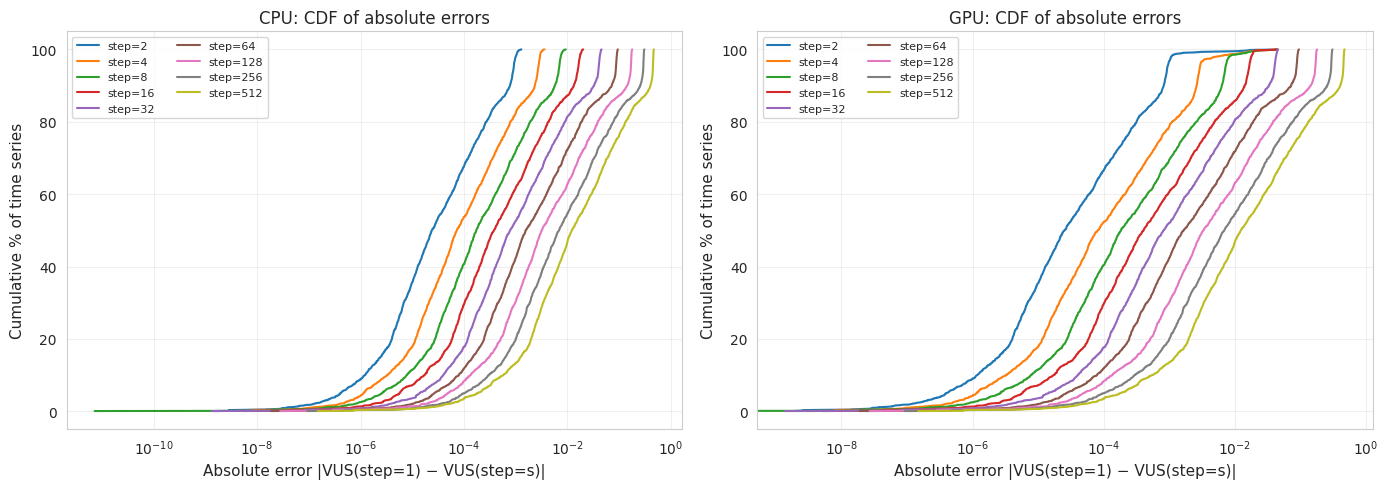


% of series with absolute error < threshold:
Backend   Step    < 1e-4    < 1e-3    < 1e-2    < 1e-1
───────────────────────────────────────────────────────
    CPU      2     67.6%     98.0%    100.0%    100.0%
    CPU      4     53.7%     82.4%    100.0%    100.0%
    CPU      8     40.6%     71.9%    100.0%    100.0%
    CPU     16     29.6%     61.6%     87.3%    100.0%
    CPU     64     11.8%     42.3%     72.3%    100.0%
    CPU    256      4.9%     19.9%     54.6%     83.0%
    CPU    512      3.4%     13.2%     46.8%     76.2%
    GPU      2     66.6%     96.8%     99.5%    100.0%
    GPU      4     52.1%     78.6%     98.7%    100.0%
    GPU      8     40.3%     69.4%     98.5%    100.0%
    GPU     16     29.7%     60.6%     85.8%    100.0%
    GPU     64     11.8%     42.4%     71.8%    100.0%
    GPU    256      4.9%     19.9%     54.5%     82.9%
    GPU    512      3.4%     13.5%     46.8%     76.5%


In [19]:
# ── 9. Heatmap: error across ALL time series for a selection of steps ────────
# This gives the reviewer a full picture of how errors distribute

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for i, backend in enumerate(['CPU', 'GPU']):
    ax = axes[i]
    bdf = err_df[err_df['Backend'] == backend]
    
    # Pivot: rows=time series, columns=step
    pivot = bdf.pivot_table(index='Time series', columns='Step', values='Abs error')
    pivot = pivot.sort_values(by=pivot.columns[-1], ascending=False)  # Sort by largest step error
    
    # Show the error distribution as a histogram/CDF for each step
    steps_to_show = [2, 4, 8, 16, 32, 64, 128, 256, 512]
    steps_to_show = [s for s in steps_to_show if s in pivot.columns]
    
    for step_val in steps_to_show:
        vals = pivot[step_val].dropna().sort_values()
        cdf = np.arange(1, len(vals)+1) / len(vals) * 100
        ax.plot(vals.values, cdf, label=f'step={step_val}', linewidth=1.5)
    
    ax.set_xlabel('Absolute error |VUS(step=1) − VUS(step=s)|', fontsize=11)
    ax.set_ylabel('Cumulative % of time series', fontsize=11)
    ax.set_title(f'{backend}: CDF of absolute errors', fontsize=12)
    ax.legend(fontsize=8, ncol=2)
    ax.set_xscale('log')
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Print the percentage of series with error < threshold for key steps
print("\n% of series with absolute error < threshold:")
print(f"{'Backend':>7s}  {'Step':>5s}  {'< 1e-4':>8s}  {'< 1e-3':>8s}  {'< 1e-2':>8s}  {'< 1e-1':>8s}")
print("─" * 55)
for backend in ['CPU', 'GPU']:
    bdf = err_df[err_df['Backend'] == backend]
    for step_val in [2, 4, 8, 16, 64, 256, 512]:
        sdf = bdf[bdf['Step'] == step_val]
        if len(sdf) == 0:
            continue
        n = len(sdf)
        pcts = [
            (sdf['Abs error'] < t).sum() / n * 100 
            for t in [1e-4, 1e-3, 1e-2, 1e-1]
        ]
        print(f"{backend:>7s}  {step_val:>5d}  {pcts[0]:>7.1f}%  {pcts[1]:>7.1f}%  {pcts[2]:>7.1f}%  {pcts[3]:>7.1f}%")

## Experiment 4: Equivalence to AUC

In [27]:
curr_experiment_path = os.path.join(experiments_path, 'vus_ffvus_auc_0_tsb', 'results')
df = load_results(curr_experiment_path)    
df['Metric'] = df['Metric'].map(formal_names)
df.sample(3)

100%|██████████| 4/4 [00:00<00:00, 80.10it/s]


,Time series,Length,Number of anomalies,Anomalies average length,Slope size,Step,Global mask,Slopes,Existence,Confusion matrix,...,Score mask time,Position time,Slopes time,Existence time,Confusion matrix time,Precision recall curve time,Integral time,Metric,Metric value,Metric time
450,OPPORTUNITY/S1-ADL5.test.csv@71.out,30047,2,609.0,0.0,1.0,True,function,0.0,dynamic_plus,...,0.000033,0.000068,0.000175,0.000001,0.000221,0.000084,0.000034,Fast-VUS-GPU (L: 128),0.177368,0.002248
6853,YAHOO/YahooA3Benchmark-TS63_data.out,1679,10,1.0,0.0,NaN,NaN,NaN,False,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,VUS (L: 128),0.122567,0.007506
4023,OPPORTUNITY/S1-ADL5.test.csv@114.out,30126,2,609.0,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,AUC,0.099563,0.002555


In [28]:
values_df = df[['Time series', 'Metric', 'Metric value']]
values_df = values_df.pivot(columns='Metric', index='Time series', values='Metric value')
dif_df = values_df.copy()
for metric in metrics: 
    dif_df[metric] = values_df[metric] - values_df['AUC']

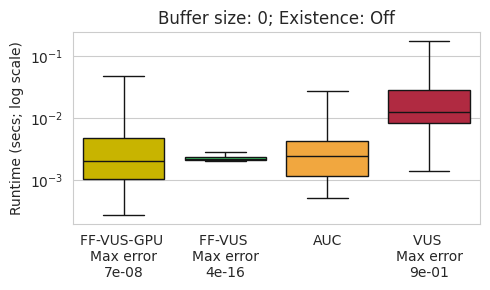

In [29]:
metrics = df['Metric'].unique()
median_times = df.groupby('Metric')['Metric time'].median()
order = median_times.sort_values().index.to_list()

fig, axis = plt.subplots(1, 1, figsize=(5, 3))
sns.boxplot(
    y='Metric time', 
    x='Metric', 
    hue='Metric', 
    data=df, 
    showfliers=False, 
    log_scale=True, 
    palette=color_palette, 
    order=order, 
    ax=axis,
    saturation=1
)
axis.set_xlabel('')
axis.set_ylabel('Runtime (secs; log scale)')
axis.set_title('Buffer size: 0; Existence: Off')
axis.set_xticks(np.arange(len(metrics)), [x.replace('(L: 128)', f'\nMax error\n{dif_df.max()[x]:.0e}') for x in metrics])

finalize_plot(save_fig_path, 'exec_time_auc_equivalence')

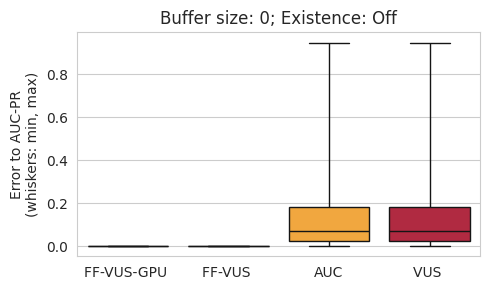

In [30]:
fig, axis = plt.subplots(1, 1, figsize=(5, 3))

sns.boxplot(
    dif_df.abs(), 
    showfliers=True, 
    palette=color_palette, 
    order=order, 
    log_scale=False, 
    ax=axis,
    saturation=1,
    whis=[0, 100]
)
axis.set_xlabel('')
axis.set_ylabel('Error to AUC-PR\n(whiskers: min, max)')
axis.set_title('Buffer size: 0; Existence: Off')
axis.set_xticks(np.arange(len(metrics)), [x.replace('(L: 128)', '(L: 0, E: Off)') for x in metrics])
axis.set_xticks(np.arange(len(metrics)), [x.replace('(L: 128)', '') for x in metrics])

finalize_plot(save_fig_path, 'error_auc_equivalence')

## Experiment 5: MSAD pipeline with VUS for evaluation 

In [137]:
curr_experiment_path = os.path.join(experiments_path, 'compare_train_metrics', 'sylli_logs_29012026')

result_files = [file for file in os.listdir(curr_experiment_path) if file.endswith('.csv')]

df = pd.DataFrame()
for file in tqdm(result_files):
    file_path = os.path.join(curr_experiment_path, file)
    curr_df = pd.read_csv(file_path, index_col=0).reset_index()
    curr_df = curr_df.rename(columns={
        'epoch': 'Epoch',
        'train_time': 'Train time',
        'val_time': 'Val time',
        'total_time': 'Total time',
        'train_pct': 'Train %',
        'val_pct': 'Val %'
    })
    curr_df['Metric'] = file.split('_')[3]
    df = pd.concat([df, curr_df], ignore_index=True)

df
df['Metric'] = df['Metric'].map(formal_names)
df = df[df['Epoch'] != 'TOTAL']
df

100%|██████████| 4/4 [00:00<00:00, 760.98it/s]


,Epoch,Train time,Val time,Total time,Train %,Val %,Metric
0,0,51.186693,0.988352,52.175045,98.105700,1.894300,AUC
1,1,48.503288,0.883242,49.386530,98.211573,1.788427,AUC
2,2,48.396307,0.817314,49.213622,98.339252,1.660748,AUC
3,3,45.818541,0.827613,46.646153,98.225764,1.774236,AUC
4,4,45.817135,0.826133,46.643268,98.228827,1.771173,AUC
...,...,...,...,...,...,...,...
398,95,47.184286,0.924664,48.108950,98.077979,1.922021,FastVUS-GPU (L: 128)
399,96,46.935867,0.933499,47.869366,98.049904,1.950096,FastVUS-GPU (L: 128)
400,97,47.172950,0.929857,48.102807,98.066938,1.933062,FastVUS-GPU (L: 128)
401,98,46.680577,0.923160,47.603737,98.060740,1.939260,FastVUS-GPU (L: 128)


In [138]:
# Per-metric aggregates
stats = df.groupby('Metric').agg(
    avg_train_per_epoch=('Train time', 'mean'),
    avg_val_per_epoch=('Val time', 'mean'),
    avg_total_per_epoch=('Total time', 'mean'),
    total_train=('Train time', 'sum'),
    total_val=('Val time', 'sum'),
    total_total=('Total time', 'sum'),
    n_epochs=('Epoch', 'count'),
).reset_index()

# Validation overhead as a % of training time (total val / total train)
stats['overhead_%'] = stats['total_val'] / stats['total_train'] * 100

# Validation speedup vs VUS (based on avg validation time per epoch).
# startswith avoids matching 'AutoVUS-GPU'.
vus_mask = stats['Metric'].str.startswith('VUS')
vus_val = stats.loc[vus_mask, 'avg_val_per_epoch'].iloc[0]
stats['val_speedup_vs_VUS'] = vus_val / stats['avg_val_per_epoch']

# ---- Print ----
print(f"{'Metric':<22} {'AvgTrain/ep (s)':>15} {'AvgVal/ep (s)':>14} {'AvgTotal/ep (s)':>16} "
      f"{'TotalTrain (s)':>15} {'TotalVal (s)':>13} {'TotalTotal (s)':>15} "
      f"{'Overhead %':>12} {'Speedup vs VUS':>16}")
print('-' * 146)
for _, r in stats.sort_values('avg_val_per_epoch', ascending=False).iterrows():
    print(f"{r['Metric']:<22} {r['avg_train_per_epoch']:>15.3f} {r['avg_val_per_epoch']:>14.3f} "
          f"{r['avg_total_per_epoch']:>16.3f} {r['total_train']:>15.1f} {r['total_val']:>13.1f} "
          f"{r['total_total']:>15.1f} {r['overhead_%']:>11.1f}% {r['val_speedup_vs_VUS']:>15.1f}x")

Metric                 AvgTrain/ep (s)  AvgVal/ep (s)  AvgTotal/ep (s)  TotalTrain (s)  TotalVal (s)  TotalTotal (s)   Overhead %   Speedup vs VUS
--------------------------------------------------------------------------------------------------------------------------------------------------
VUS (L: 128)                    46.923        132.285          179.208          4692.3       13228.5         17920.8       281.9%             1.0x
FastVUS (L: 128)                46.305          3.014           49.319          4630.5         301.4          4931.9         6.5%            43.9x
FastVUS-GPU (L: 128)            47.379          0.930           48.309          4737.9          93.0          4830.9         2.0%           142.3x
AUC                             47.744          0.908           48.652          4774.4          90.8          4865.2         1.9%           145.7x


In [139]:
grouped = df.groupby('Metric')[['Train time', 'Val time', 'Total time']].sum().reset_index()
metric_order = ['VUS (L: 128)', f'{my_vus_name} (L: 128)', f'{my_vus_name}-GPU (L: 128)', 'AUC']
grouped_sorted = grouped.set_index('Metric').loc[metric_order].reset_index()
grouped_sorted

,Metric,Train time,Val time,Total time
0,VUS (L: 128),4692.285551,13228.497365,17920.782916
1,FastVUS (L: 128),4630.477214,301.407007,4931.884221
2,FastVUS-GPU (L: 128),4737.914083,92.991771,4830.905854
3,AUC,4774.420968,90.783151,4865.204119


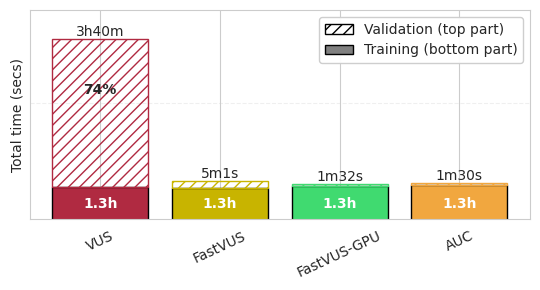

In [196]:
from matplotlib.patches import Patch
from matplotlib.ticker import NullFormatter

fig, ax = plt.subplots(1, 1, figsize=(5.5, 3))

train_times = grouped_sorted['Train time'].values
val_times = grouped_sorted['Val time'].values
x_pos = np.arange(len(grouped_sorted))

# Create stacked bars
bars1 = ax.bar(x_pos, train_times, color=[color_palette[m] for m in grouped_sorted['Metric']], edgecolor='black', label='Training (bottom part)')
bars2 = ax.bar(x_pos, val_times, bottom=train_times, color='none', edgecolor=[color_palette[m] for m in grouped_sorted['Metric']], hatch='///', linewidth=1, label='Validation (top part)')

ax.set_xticks(x_pos)
ax.set_xticklabels([x.replace(' (L: 128)', '') for x in metric_order], rotation=25)

ax.set_yscale('log')
# yticks = [3600, 7200, 10800, 14400, 18000, 21600, 25200, 28800, 32400, 36000]
# ylabels = ['1h', '2h', '3h', '4h', '5h', '6h', '7h', '8h', '9h', '10h']
# ax.set_yticks(yticks[0::2])
# ax.set_yticklabels(ylabels[::2])
# ax.yaxis.set_minor_formatter(NullFormatter())  # hide log minor-tick labels (2x10^4 etc.)
ax.set_ylabel('Total time (secs)')
ax.set_ylim(3500, max(grouped_sorted['Total time'])*1.3)
ax.tick_params(axis='y', which='both', left=False, labelleft=False)

legend_handles = [
    Patch(facecolor='none', edgecolor='black', hatch='///', linewidth=1, label='Validation (top part)'),
    Patch(facecolor='gray', edgecolor='black', label='Training (bottom part)'),
]
ax.legend(handles=legend_handles, loc='upper right', framealpha=0.95)
ax.grid(axis='y', alpha=0.3, linestyle='--')

# Add total time labels on top
for i, (val, total) in enumerate(zip(val_times, grouped_sorted['Total time'])):
    if val >= 3600:
        hrs = int(val // 3600)
        mins = int((val % 3600) // 60)
        ax.text(i, total + 3, f'{hrs}h{mins}m', ha='center', va='bottom')
    elif val >= 60:
        ax.text(i, total + 3, f'{int(val // 60)}m{int(val % 60)}s', ha='center', va='bottom')
    else:
        ax.text(i, total + 3, f'{val:.1f}s', ha='center', va='bottom')

# Add validation overhead percentage labels on the orange section
for i, (train, val, total) in enumerate(zip(train_times, val_times, grouped_sorted['Total time'])):
    val_pct = (val/total) * 100
    # ax.text(i, 4000, f'{train/3600 - 0.05:.1f}h', ha='center', va='center', weight='bold', color='white')
    ax.text(i, 4000, f'1.3h', ha='center', va='center', weight='bold', color='white')
    if val_pct > 8:  # Only label if significant enough
        ax.text(i, train + val/2, f'{val_pct:.0f}%', ha='center', va='center', weight='bold')

# ax.set_title('Total time breakdown')
finalize_plot(save_fig_path, 'toy_example_time_breakdown')

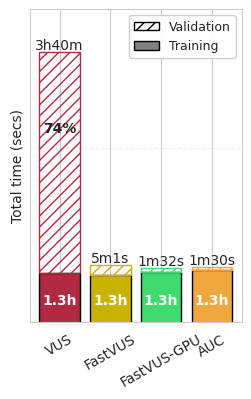

In [202]:
from matplotlib.patches import Patch
from matplotlib.ticker import NullFormatter

fig, ax = plt.subplots(1, 1, figsize=(5.5/2.1, 4.1))

train_times = grouped_sorted['Train time'].values
val_times = grouped_sorted['Val time'].values
x_pos = np.arange(len(grouped_sorted))

# Create stacked bars
bars1 = ax.bar(x_pos, train_times, color=[color_palette[m] for m in grouped_sorted['Metric']], edgecolor='black', label='Training (bottom part)')
bars2 = ax.bar(x_pos, val_times, bottom=train_times, color='none', edgecolor=[color_palette[m] for m in grouped_sorted['Metric']], hatch='///', linewidth=1, label='Validation (top part)')

ax.set_xticks(x_pos)
ax.set_xticklabels([x.replace(' (L: 128)', '') for x in metric_order], rotation=30)

ax.set_yscale('log')
# yticks = [3600, 7200, 10800, 14400, 18000, 21600, 25200, 28800, 32400, 36000]
# ylabels = ['1h', '2h', '3h', '4h', '5h', '6h', '7h', '8h', '9h', '10h']
# ax.set_yticks(yticks[0::2])
# ax.set_yticklabels(ylabels[::2])
# ax.yaxis.set_minor_formatter(NullFormatter())  # hide log minor-tick labels (2x10^4 etc.)
ax.set_ylabel('Total time (secs)')
ax.set_ylim(3500, max(grouped_sorted['Total time'])*1.3)
ax.tick_params(axis='y', which='both', left=False, labelleft=False)

legend_handles = [
    Patch(facecolor='none', edgecolor='black', hatch='///', linewidth=1, label='Validation'),
    Patch(facecolor='gray', edgecolor='black', label='Training'),
]
ax.legend(handles=legend_handles, loc='upper right', framealpha=0.95, fontsize=9)
ax.grid(axis='y', alpha=0.3, linestyle='--')

# Add total time labels on top
for i, (val, total) in enumerate(zip(val_times, grouped_sorted['Total time'])):
    if val >= 3600:
        hrs = int(val // 3600)
        mins = int((val % 3600) // 60)
        ax.text(i, total + 3, f'{hrs}h{mins}m', ha='center', va='bottom')
    elif val >= 60:
        ax.text(i, total + 3, f'{int(val // 60)}m{int(val % 60)}s', ha='center', va='bottom')
    else:
        ax.text(i, total + 3, f'{val:.1f}s', ha='center', va='bottom')

# Add validation overhead percentage labels on the orange section
for i, (train, val, total) in enumerate(zip(train_times, val_times, grouped_sorted['Total time'])):
    val_pct = (val/total) * 100
    # ax.text(i, 4000, f'{train/3600 - 0.05:.1f}h', ha='center', va='center', weight='bold', color='white')
    ax.text(i, 4000, f'1.3h', ha='center', va='center', weight='bold', color='white')
    if val_pct > 8:  # Only label if significant enough
        ax.text(i, train + val/2, f'{val_pct:.0f}%', ha='center', va='center', weight='bold')

# ax.set_title('Total time breakdown')
finalize_plot(save_fig_path, 'toy_example_time_breakdown_small')

In [141]:
grouped_mean = df.groupby('Metric')[['Train time', 'Val time', 'Total time']].mean()
grouped_mean

,Train time,Val time,Total time
Metric,,,
AUC,47.744210,0.907832,48.652041
FastVUS (L: 128),46.304772,3.014070,49.318842
FastVUS-GPU (L: 128),47.379141,0.929918,48.309059
VUS (L: 128),46.922856,132.284974,179.207829


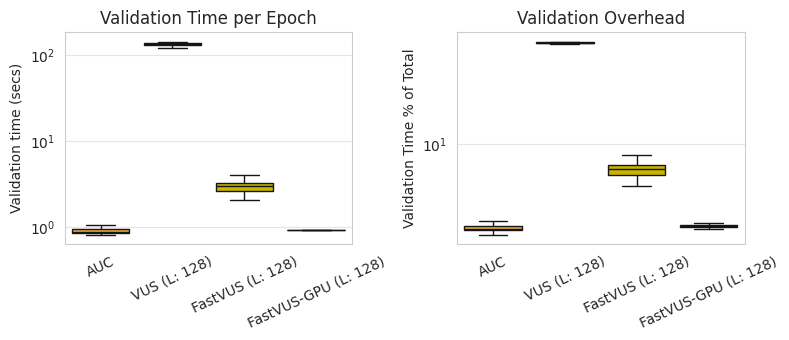

In [142]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3.5))

# Left plot: Validation time comparison
ax1 = axes[0]
df_plot = df[df['Epoch'] != 'TOTAL'].copy()
df_plot['Val time'] = df_plot['Val time'].astype(float)

sns.boxplot(
    data=df_plot,
    x='Metric',
    y='Val time',
    hue='Metric',
    palette=color_palette,
    ax=ax1,
    saturation=1,
    showfliers=False,
    log_scale=True
)
ax1.set_ylabel('Validation time (secs)')
ax1.set_xlabel('')
ax1.set_title('Validation Time per Epoch')
ax1.tick_params(axis='x', rotation=25)
ax1.grid(axis='y', alpha=0.5)

# Right plot: Val % (overhead) comparison
ax2 = axes[1]
df_plot['Val %'] = df_plot['Val %'].astype(float)

sns.boxplot(
    data=df_plot,
    x='Metric',
    y='Val %',
    hue='Metric',
    palette=color_palette,
    ax=ax2,
    saturation=1,
    showfliers=False,
    log_scale=True
)
ax2.set_ylabel('Validation Time % of Total')
ax2.set_xlabel('')
ax2.set_title('Validation Overhead')
ax2.tick_params(axis='x', rotation=25)
ax2.grid(axis='y', alpha=0.5)

finalize_plot(save_fig_path, 'msad_pipeline_validation_overhead')

Validation Time per Epoch


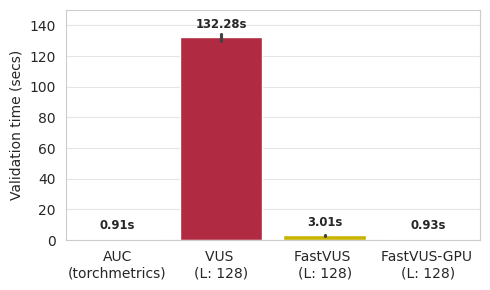

In [143]:
fig, axes = plt.subplots(1, 1, figsize=(5, 3))
df_plot = df[df['Epoch'] != 'TOTAL'].copy()
df_plot['Val time'] = df_plot['Val time'].astype(float)

sns.barplot(
    data=df_plot,
    x='Metric',
    y='Val time',
    hue='Metric',
    palette=color_palette,
    ax=axes,
    saturation=1,
)
# axes.set_title('Validation Time per Epoch')
print('Validation Time per Epoch')
axes.set_ylabel('Validation time (secs)')
axes.set_xlabel('')
axes.tick_params(axis='x', rotation=0)
axes.grid(axis='y', alpha=0.5)
axes.set_ylim(0, 150)

# Add mean validation times on top of each bar
mean_val_times = df_plot.groupby('Metric')['Val time'].mean()
for i, metric in enumerate(axes.get_xticklabels()):
    metric_name = metric.get_text()
    mean_time = mean_val_times.get(metric_name, 0)
    axes.text(i, mean_time + 4.2, f'{mean_time:.2f}s', ha='center', va='bottom', fontsize='small', fontweight='bold')

# Add '(torchmetrics)' below 'AUC' label
xticklabels = axes.get_xticklabels()
for label in xticklabels:
    if label.get_text() == 'AUC':
        label.set_text('AUC(torchmetrics)')
    if '(' in label.get_text():
        label.set_text(label.get_text().replace('(', '\n('))
axes.set_xticks(np.arange(4), xticklabels)

finalize_plot(save_fig_path, 'msad_pipeline_validation_overhead_barplot')

In [144]:
print("Fast-VUS metrics add minimal overhead\nwhile providing advanced evaluation")
df_plot.groupby('Metric')['Val time'].mean()

Fast-VUS metrics add minimal overhead
while providing advanced evaluation


Metric
AUC                       0.907832
FastVUS (L: 128)          3.014070
FastVUS-GPU (L: 128)      0.929918
VUS (L: 128)            132.284974
Name: Val time, dtype: float64

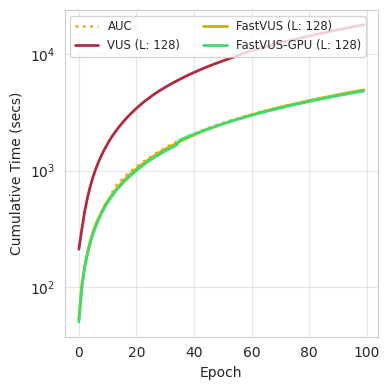

In [145]:
fig, axis = plt.subplots(1, 1, figsize=(4, 4))

df_plot = df[df['Epoch'] != 'TOTAL'].copy()
df_plot['Train time'] = df_plot['Train time'].astype(float)
df_plot['Val time'] = df_plot['Val time'].astype(float)
df_plot['Epoch'] = df_plot['Epoch'].astype(int)

for metric in df_plot['Metric'].unique():
    metric_data = df_plot[df_plot['Metric'] == metric].sort_values('Epoch')
    # Calculate cumulative times
    metric_data = metric_data.copy()
    metric_data['Train time'] = metric_data['Train time'].cumsum()
    metric_data['Val time'] = metric_data['Val time'].cumsum()
    
    color = color_palette[metric]
    
    # Solid line for validation time
    # axis.plot(metric_data['Epoch'], metric_data['Val time'], 
    #           color=color, linewidth=2, label=f'{metric} (Val)', linestyle='-')
    
    # # Dotted line for training time
    # axis.plot(metric_data['Epoch'], metric_data['Train time'], 
    #           color=color, linewidth=4, label=f'{metric} (Train)', linestyle='dotted')
    
    # Total time with different line styles for each metric
    linestyles = {
        'VUS (L: 128)': '-',
        'Fast-VUS (L: 128)': '--',
        'Fast-VUS-GPU (L: 128)': '-.',
        'AUC': ':'
    }
    axis.plot(metric_data['Epoch'], metric_data['Train time'] + metric_data['Val time'], 
        color=color, linewidth=2, label=f'{metric}', linestyle=linestyles.get(metric, '-'))

axis.set_xlabel('Epoch')
axis.set_ylabel('Cumulative Time (secs)')
# axis.set_title('Cumulative Training and Validation Time per Epoch')
axis.grid(axis='both', alpha=0.5)
axis.legend(ncol=2, fontsize='small', loc='upper left')
axis.set_yscale('log')


finalize_plot(save_fig_path, 'cumulative_time_time_per_epoch')

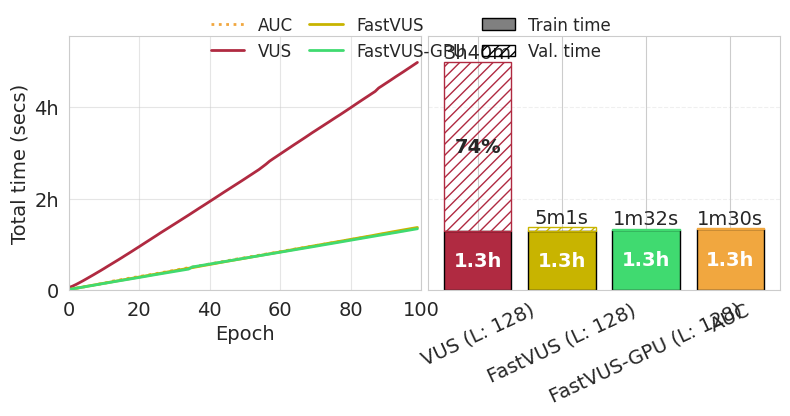

Figure X: Training time comparison for MSAD model selection. (Left) Cumulative training time across 100 epochs showing VUS validation overhead dominates total runtime. (Right) Stacked bar chart decomposing total training time into training (solid) and validation (hatched) components. VUS incurs ~74% validation overhead, while Fast-VUS-GPU achieves comparable evaluation quality with <2% overhead, matching AUC-PR efficiency.


In [146]:
from matplotlib.patches import Patch

fig, axes = plt.subplots(1, 2, figsize=(8, 4), sharey=True)


ax = axes[1]
train_times = grouped_sorted['Train time'].values
val_times = grouped_sorted['Val time'].values
x_pos = np.arange(len(grouped_sorted))

# Create stacked bars
bars1 = ax.bar(x_pos, train_times, color=[color_palette[m] for m in grouped_sorted['Metric']], edgecolor='black', label='Training (bottom part)')
bars2 = ax.bar(x_pos, val_times, bottom=train_times, color='none', edgecolor=[color_palette[m] for m in grouped_sorted['Metric']], hatch='///', linewidth=1, label='Validation (top part)')

ax.set_xticks(x_pos)
ax.set_xticklabels(metric_order, rotation=25, fontsize=14) # + ('\n(L: 512)' if 'VUS' in m else '')
legend_handles = [
    Patch(facecolor='black', edgecolor='black', label='Train time'),
    Patch(facecolor='none', edgecolor='black', hatch='///', linewidth=1, label='Validation time')
]
ax.legend(handles=legend_handles, loc='upper right', framealpha=0.95)
ax.grid(axis='y', alpha=0.3, linestyle='--')

# Add total time labels on top
for i, (val, total) in enumerate(zip(val_times, grouped_sorted['Total time'])):
    if val >= 3600:
        hrs = int(val // 3600)
        mins = int((val % 3600) // 60)
        ax.text(i, total + 3, f'{hrs}h{mins}m', ha='center', va='bottom', size=14)
    elif val >= 60:
        ax.text(i, total + 3, f'{int(val // 60)}m{int(val % 60)}s', ha='center', va='bottom', size=14)
    else:
        ax.text(i, total + 3, f'{val:.1f}s', ha='center', va='bottom', size=14)

# Add validation overhead percentage labels on the orange section
for i, (train, val, total) in enumerate(zip(train_times, val_times, grouped_sorted['Total time'])):
    val_pct = (val/(train+val)) * 100
    hrs = int(train // 3600)
    mins = int((train % 3600) // 60)
    # ax.text(i, train/2, f'{hrs}h{mins}m', ha='center', va='center', weight='bold', color='white')
    ax.text(i, train/2, f'{train/3600:.1f}h', ha='center', va='center', weight='bold', color='white', size=14)

    if val_pct > 8:
        ax.text(i, train + val/2, f'{val_pct:.0f}%', ha='center', va='center', weight='bold', size=14)

# ---------------------------
axis = axes[0]

df_plot = df[df['Epoch'] != 'TOTAL'].copy()
df_plot['Epoch'] = df_plot['Epoch'].astype(int)

for metric in df_plot['Metric'].unique():
    metric_data = df_plot[df_plot['Metric'] == metric].sort_values('Epoch')

    metric_data = metric_data.copy()
    metric_data['Train time'] = metric_data['Train time'].cumsum()
    metric_data['Val time'] = metric_data['Val time'].cumsum()
    
    color = color_palette[metric]
    linestyles = {
        'VUS (L: 128)': '-',
        'Fast-VUS (L: 128)': '--',
        'Fast-VUS-GPU (L: 128)': '-.',
        'AUC': ':'
    }
    axis.plot(metric_data['Epoch'], metric_data['Train time'] + metric_data['Val time'], 
        color=color, linewidth=2, label=f'{metric}', linestyle=linestyles.get(metric, '-'))

axis.set_xlabel('Epoch', size=14)
axis.set_ylabel('Total time (secs)', size=14)
axis.set_xticks(ticks=axis.get_xticks(), labels=axis.get_xticklabels(), fontsize=14)
axis.set_yticks(ticks=[0, 7200, 14400], labels=['0', '2h', '4h'], fontsize=14)
axis.set_ylim(0, 20000)
axis.grid(axis='both', alpha=0.5)
# axis.legend(ncol=2, fontsize='small', loc='upper left')
axis.set_xlim(0, 100)

handles, labels = axis.get_legend_handles_labels()
handles += [
    Patch(facecolor='gray', edgecolor='black', label='Train time'),
    Patch(facecolor='none', edgecolor='black', hatch='///', linewidth=1, label='Validation time')
]
labels += ['Train time', 'Val. time']
labels = [label.replace(' (L: 128)', '').replace(' mean', '') for label in labels]
ax.get_legend().remove()
fig.legend(
    handles,
    labels,
    loc='upper center',
    bbox_to_anchor=(0.52, 1.05),
    ncol=len(labels)//2,
    frameon=False,
    fontsize='large',
    columnspacing=1.0
)

plt.tight_layout()
fig.subplots_adjust(wspace=0.02)
save_path = os.path.join(save_fig_path, 'toy_example_combined')
plt.savefig(f"{save_path}.pdf", bbox_inches='tight', pad_inches=0)
plt.show()

print("Figure X: Training time comparison for MSAD model selection. (Left) Cumulative training time across 100 epochs showing VUS validation overhead dominates total runtime. (Right) Stacked bar chart decomposing total training time into training (solid) and validation (hatched) components. VUS incurs ~74% validation overhead, while Fast-VUS-GPU achieves comparable evaluation quality with <2% overhead, matching AUC-PR efficiency.")

In [148]:
df_plot = df[df['Epoch'] != 'TOTAL'].copy()

grouped = df_plot.groupby('Metric')[['Train time', 'Val time', 'Total time']].sum().reset_index()
metric_order = ['VUS (L: 128)', f'{my_vus_name} (L: 128)', f'{my_vus_name}-GPU (L: 128)', 'AUC']
# metric_order = ['Fast-VUS (L: 128)', 'Fast-VUS-GPU (L: 128)', 'AUC']
grouped_sorted = grouped.set_index('Metric').loc[metric_order].reset_index()
# Print grouped_sorted with times in appropriate units
for _, row in grouped_sorted.iterrows():
    metric = row['Metric']
    train_secs = row['Train time']
    val_secs = row['Val time']
    total_secs = row['Total time']
    
    def format_time(secs):
        if secs >= 3600:
            return f"{secs/3600:.0f}h{((secs%3600)/60):.0f}m"
        elif secs >= 60:
            return f"{secs/60:.1f}m"
        else:
            return f"{secs:.1f}s"
    
    print(f"{metric}: Train={format_time(train_secs)}, Val={format_time(val_secs)}, Total={format_time(total_secs)}")

grouped_sorted

VUS (L: 128): Train=1h18m, Val=4h40m, Total=5h59m
FastVUS (L: 128): Train=1h17m, Val=5.0m, Total=1h22m
FastVUS-GPU (L: 128): Train=1h19m, Val=1.5m, Total=1h21m
AUC: Train=1h20m, Val=1.5m, Total=1h21m


,Metric,Train time,Val time,Total time
0,VUS (L: 128),4692.285551,13228.497365,17920.782916
1,FastVUS (L: 128),4630.477214,301.407007,4931.884221
2,FastVUS-GPU (L: 128),4737.914083,92.991771,4830.905854
3,AUC,4774.420968,90.783151,4865.204119


## Experiment: Compare existence algorithms


In [12]:
curr_experiment_path = os.path.join(experiments_path, 'existence_comparison')
existence_df = pd.read_csv(os.path.join(curr_experiment_path, 'tsb_all_128.csv'))

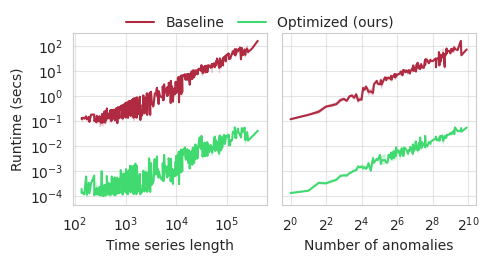

In [45]:

fig, axes = plt.subplots(1, 2, figsize=(5, 2.5), sharey=True)

ax = axes[0]
# existence_df_sorted = existence_df.sort_values('T')
# existence_df_smooth = existence_df_sorted.rolling(1).mean()

sns.lineplot(data=existence_df, x='T', y='trivial_mean', label='Baseline', color='#b02a41', ax=ax)
sns.lineplot(data=existence_df, x='T', y='optimized_mean', label='Optimized (ours)', color='#40da70', ax=ax)
ax.set_xlabel('Time series length')
ax.set_ylabel('Runtime (secs)')
ax.set_yscale('log')
ax.set_xscale('log', base=10)
ax.grid(axis='both', alpha=0.5)
ax.legend().remove()
ax.set_yticks([10**x for x in range(-4, 3)])
ax.set_xticks([10**x for x in range(2, 6)])

ax = axes[1]
existence_df_sorted = existence_df.sort_values('n_anomalies')
sns.lineplot(data=existence_df, x='n_anomalies', y='trivial_mean', label='Baseline', color='#b02a41', ax=ax)
sns.lineplot(data=existence_df, x='n_anomalies', y='optimized_mean', label='Optimized (ours)', color='#40da70', ax=ax)
ax.set_xlabel('Number of anomalies')
ax.set_ylabel('')
ax.set_yscale('log')
ax.grid(axis='both', alpha=0.5)
ax.set_xscale('log', base=2)
ax.set_yticks([10**x for x in range(-4, 3)])
# ax.set_xticks([2**x for x in range(0, 11, 2)], [2**x for x in range(0, 11, 2)])
ax.set_xticks([2**x for x in range(0, 11, 2)])

handles, labels = ax.get_legend_handles_labels()
ax.get_legend().remove()
fig.legend(
    handles,
    labels,
    loc='upper center',
    bbox_to_anchor=(0.53, 1.06),
    ncol=len(labels),
    frameon=False,
    fontsize='medium',
    columnspacing=1.0
)

finalize_plot(save_fig_path, 'existence_comparison')

In [46]:
# Analyze speedup of optimized existence algorithm over trivial implementation
print("="*70)
print("EXISTENCE ALGORITHM OPTIMIZATION ANALYSIS")
print("="*70)

# Overall statistics
print("\nOVERALL SPEEDUP:")
print(f"  Mean speedup: {existence_df['speedup'].mean():.1f}×")
print(f"  Median speedup: {existence_df['speedup'].median():.1f}×")
print(f"  Min speedup: {existence_df['speedup'].min():.1f}×")
print(f"  Max speedup: {existence_df['speedup'].max():.1f}×")

# Speedup by time series length
print("\nSPEEDUP BY TIME SERIES LENGTH:")
length_groups = existence_df.groupby(pd.cut(existence_df['T'], bins=5))
for interval, group in length_groups:
    print(f"  Length {interval}: {group['speedup'].mean():.1f}× (n={len(group)})")

# Speedup by number of anomalies
print("\nSPEEDUP BY NUMBER OF ANOMALIES:")
anomaly_groups = existence_df.groupby('n_anomalies')
for n_anom, group in anomaly_groups:
    print(f"  {n_anom} anomalies: {group['speedup'].mean():.1f}× (n={len(group)})")

# Absolute time comparison
print("\nABSOLUTE TIMING:")
print(f"  Trivial implementation:")
print(f"    Mean time: {existence_df['trivial_mean'].mean():.4f}s")
print(f"    Max time:  {existence_df['trivial_mean'].max():.4f}s")
print(f"  Optimized implementation:")
print(f"    Mean time: {existence_df['optimized_mean'].mean():.6f}s")
print(f"    Max time:  {existence_df['optimized_mean'].max():.6f}s")

# Correctness verification
print("\nCORRECTNESS VERIFICATION:")
print(f"  All results match: {existence_df['matches'].all()}")
print(f"  Max difference: {existence_df['max_diff'].max():.2e}")
print(f"  Mean difference: {existence_df['mean_diff'].mean():.2e}")

# Large-scale problem analysis
print("\nLARGE-SCALE PROBLEMS (>100k time series length):")
large_scale = existence_df[existence_df['T'] > 100000]
if len(large_scale) > 0:
    print(f"  Number of problems: {len(large_scale)}")
    print(f"  Mean speedup: {large_scale['speedup'].mean():.1f}×")
    print(f"  Trivial time: {large_scale['trivial_mean'].mean():.2f}s")
    print(f"  Optimized time: {large_scale['optimized_mean'].mean():.4f}s")

print("\n" + "="*70)

EXISTENCE ALGORITHM OPTIMIZATION ANALYSIS

OVERALL SPEEDUP:
  Mean speedup: 1157.7×
  Median speedup: 1120.2×
  Min speedup: 25.7×
  Max speedup: 4177.5×

SPEEDUP BY TIME SERIES LENGTH:
  Length (-267.737, 80883.4]: 1125.3× (n=1971)
  Length (80883.4, 161630.8]: 1936.4× (n=45)
  Length (161630.8, 242378.2]: 2034.4× (n=16)
  Length (242378.2, 323125.6]: 2998.1× (n=5)
  Length (323125.6, 403873.0]: 4016.0× (n=2)

SPEEDUP BY NUMBER OF ANOMALIES:
  1 anomalies: 949.6× (n=508)
  2 anomalies: 1136.3× (n=556)
  3 anomalies: 803.3× (n=117)
  4 anomalies: 1233.5× (n=65)
  5 anomalies: 1223.2× (n=50)
  6 anomalies: 1134.3× (n=59)
  7 anomalies: 1114.4× (n=28)
  8 anomalies: 1212.0× (n=35)
  9 anomalies: 1076.1× (n=27)
  10 anomalies: 1248.2× (n=65)
  11 anomalies: 1231.5× (n=38)
  12 anomalies: 955.5× (n=29)
  13 anomalies: 1210.0× (n=51)
  14 anomalies: 485.9× (n=16)
  15 anomalies: 582.5× (n=17)
  16 anomalies: 472.1× (n=14)
  17 anomalies: 1732.8× (n=3)
  18 anomalies: 1234.6× (n=2)
  19 anom

/tmp/ipykernel_7625/895005727.py:15: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  length_groups = existence_df.groupby(pd.cut(existence_df['T'], bins=5))


## VUS evaluation time VS detectors runtime

In [12]:
vus_metrics = ['VUS (L: 128)', f'{my_vus_name} (L: 128)', f'{my_vus_name}-GPU (L: 128)']

vus_times = (
    df[df['Metric'].isin(vus_metrics)]
    .pivot_table(index=['Time series', 'Detector'],
                 columns='Metric',
                 values='Metric time')
    .reset_index()
    [['Time series', 'Detector'] + vus_metrics]   # fix column order
)
vus_times.columns.name = None
vus_times.head(5)

,Time series,Detector,VUS (L: 128),FastVUS (L: 128),FastVUS-GPU (L: 128)
0,001_NAB_id_1_Facility_tr_1007_1st_2014.csv,AnomalyTransformer,0.113536,0.002825,0.002900
1,001_NAB_id_1_Facility_tr_1007_1st_2014.csv,AutoEncoder,0.430118,0.002663,0.002051
2,001_NAB_id_1_Facility_tr_1007_1st_2014.csv,CNN,0.434752,0.002640,0.001977
3,001_NAB_id_1_Facility_tr_1007_1st_2014.csv,Chronos,0.427510,0.005584,0.002019
4,001_NAB_id_1_Facility_tr_1007_1st_2014.csv,Donut,0.429886,0.002444,0.001987


In [13]:
from tsad_parser import TSADParser

detector_times = (
    TSADParser().load_runtime()[['File Name', 'Model Name', 'Time Cost']]
    .rename(columns={'File Name': 'Time series',
                     'Model Name': 'Detector',
                     'Time Cost': 'Detector time'})
)
detector_times = detector_times[detector_times['Detector time'] > 0]  # drop unrecorded (0s) runs
detector_times.head(5)

,Time series,Detector,Detector time
0,001_NAB_id_1_Facility_tr_1007_1st_2014.csv,AnomalyTransformer,22.070
1,002_NAB_id_2_WebService_tr_1500_1st_4106.csv,AnomalyTransformer,24.360
2,003_NAB_id_3_WebService_tr_1362_1st_1462.csv,AnomalyTransformer,42.173
3,004_NAB_id_4_Facility_tr_1007_1st_1437.csv,AnomalyTransformer,43.374
4,005_NAB_id_5_Traffic_tr_594_1st_1645.csv,AnomalyTransformer,7.923


In [14]:
merged = vus_times.merge(detector_times, on=['Time series', 'Detector'], how='inner')
merged

,Time series,Detector,VUS (L: 128),FastVUS (L: 128),FastVUS-GPU (L: 128),Detector time
0,001_NAB_id_1_Facility_tr_1007_1st_2014.csv,AnomalyTransformer,0.113536,0.002825,0.002900,22.070
1,001_NAB_id_1_Facility_tr_1007_1st_2014.csv,AutoEncoder,0.430118,0.002663,0.002051,3.053
2,001_NAB_id_1_Facility_tr_1007_1st_2014.csv,CNN,0.434752,0.002640,0.001977,3.117
3,001_NAB_id_1_Facility_tr_1007_1st_2014.csv,Chronos,0.427510,0.005584,0.002019,13.370
4,001_NAB_id_1_Facility_tr_1007_1st_2014.csv,Donut,0.429886,0.002444,0.001987,5.118
...,...,...,...,...,...,...
24446,870_OPPORTUNITY_id_29_HumanActivity_tr_1477_1s...,Sub_PCA,0.368913,0.005906,0.002066,0.137
24447,870_OPPORTUNITY_id_29_HumanActivity_tr_1477_1s...,TimesFM,0.368041,0.007930,0.002028,60.138
24448,870_OPPORTUNITY_id_29_HumanActivity_tr_1477_1s...,TimesNet,0.370495,0.007885,0.001982,18.927
24449,870_OPPORTUNITY_id_29_HumanActivity_tr_1477_1s...,TranAD,0.402809,0.022805,0.001946,1.687


VUS eval slower than inference: 30.0% of pairs, 8/32 detectors (median)


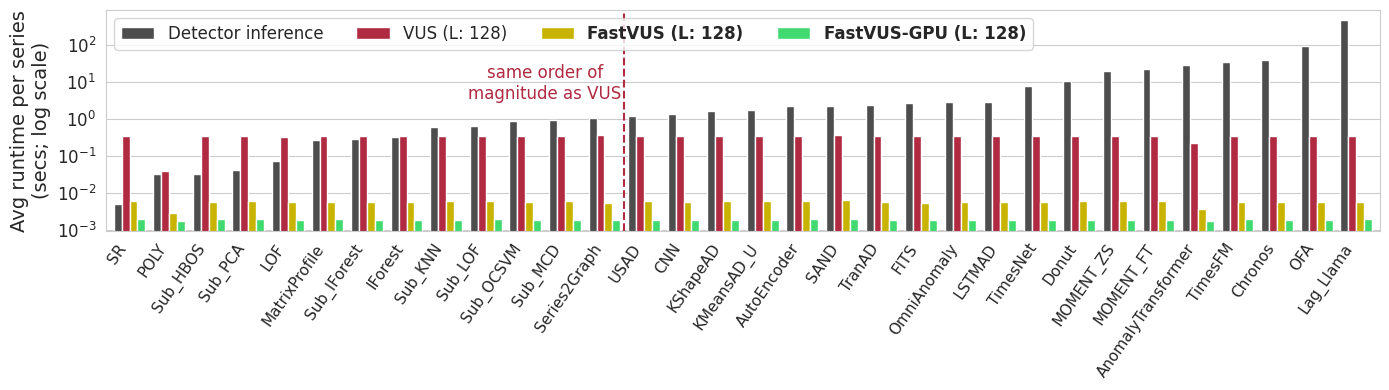

In [15]:
# Detector inference vs VUS evaluation, per detector (paper figure)
metric_cols = ['VUS (L: 128)', f'{my_vus_name} (L: 128)', f'{my_vus_name}-GPU (L: 128)']
det_color = '#4d4d4d'  # detector inference: no palette entry -> neutral grey

per_det = (merged.groupby('Detector')
           .agg(**{'Detector inference': ('Detector time', 'median'),
                   **{m: (m, 'median') for m in metric_cols}})
           .sort_values('Detector inference'))

bars   = ['Detector inference'] + metric_cols
colors = [det_color] + [color_palette[m] for m in metric_cols]

fig, axis = plt.subplots(figsize=(14, 4))
x = np.arange(len(per_det)); w = 0.8 / len(bars)
for j, (name, c) in enumerate(zip(bars, colors)):
    axis.bar(x + (j - (len(bars) - 1) / 2) * w, per_det[name], w, label=name, color=c)

axis.set_yscale('log')
axis.set_ylabel('Avg runtime per series\n(secs; log scale)', fontsize=14)
axis.set_xlabel('')
axis.set_xticks(x)
axis.set_xticklabels(per_det.index, rotation=55, ha='right', fontsize=11)
axis.tick_params(axis='y', labelsize=12)
axis.set_xlim(-0.6, len(per_det) - 0.4)
axis.grid(visible=False, axis='x')

# bold the AutoVUS entries in the legend
leg = axis.legend(ncol=4, fontsize=12, loc='upper left')
for t in leg.get_texts():
    if my_vus_name in t.get_text():
        t.set_fontweight('bold')

pair_slower = (merged['VUS (L: 128)'] >= merged['Detector time']).mean() * 100
n_det_slower = int((per_det['VUS (L: 128)'] >= per_det['Detector inference']).sum())
print(f'VUS eval slower than inference: {pair_slower:.1f}% of pairs, '
      f'{n_det_slower}/{len(per_det)} detectors (median)')

# vertical band: detectors whose inference is within the same order of magnitude as VUS runtime
vus_level = merged['VUS (L: 128)'].median()
low, high = vus_level / np.sqrt(10), vus_level * np.sqrt(10)   # one decade centered on VUS
same_oom = np.where((per_det['Detector inference'] >= low) &
                    (per_det['Detector inference'] <= high))[0]
lo, hi = same_oom.min() - 0.5, same_oom.max() + 0.5
axis.axvline(hi, ls='--', lw=1.5, color='#b02a41')
axis.text(hi - 2, 30, 'same order of\nmagnitude as VUS',
          ha='center', va='top', fontsize=12, color='#b02a41')

finalize_plot(save_fig_path, 'runtime_vs_detector_tsb_bars')

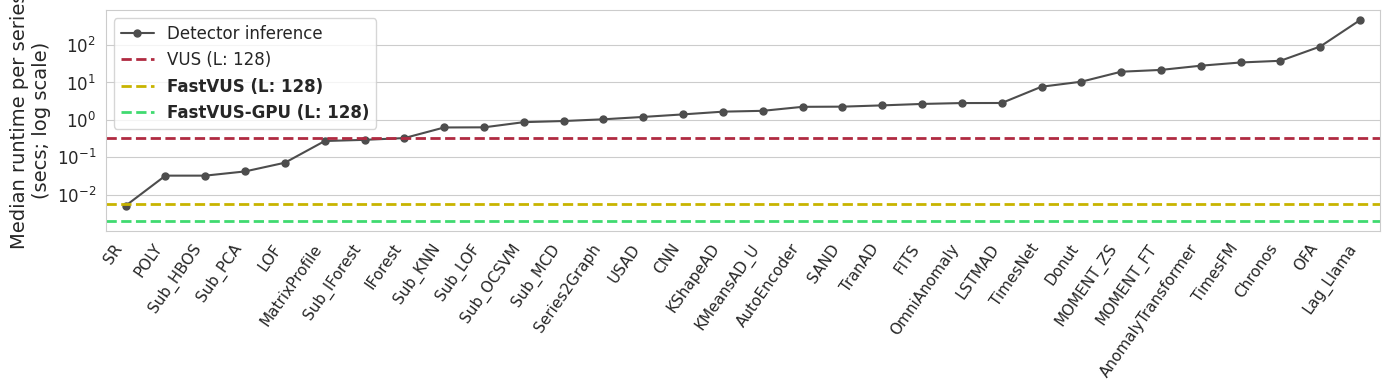

In [16]:
# Simple line plot: detector inference (line + dots) vs the 3 VUS metrics as horizontal lines
metric_cols = ['VUS (L: 128)', f'{my_vus_name} (L: 128)', f'{my_vus_name}-GPU (L: 128)']

per_det = (merged.groupby('Detector')['Detector time'].median()
           .sort_values())
x = np.arange(len(per_det))

fig, axis = plt.subplots(figsize=(14, 4))

# detector inference: line with dots, increasing order
axis.plot(x, per_det.values, '-o', color='#4d4d4d', ms=5, lw=1.5, label='Detector inference')

# each VUS metric: a single horizontal line at its median runtime (roughly detector-independent)
for m in metric_cols:
    level = merged[m].median()
    axis.axhline(level, ls='--', lw=2, color=color_palette[m], label=m)

axis.set_yscale('log')
axis.set_ylabel('Median runtime per series\n(secs; log scale)', fontsize=14)
axis.set_xlabel('')
axis.set_xticks(x)
axis.set_xticklabels(per_det.index, rotation=55, ha='right', fontsize=11)
axis.tick_params(axis='y', labelsize=12)
axis.set_xlim(-0.5, len(per_det) - 0.5)
axis.grid(visible=False, axis='x')

leg = axis.legend(fontsize=12, loc='upper left')
for t in leg.get_texts():
    if my_vus_name in t.get_text():
        t.set_fontweight('bold')

finalize_plot(save_fig_path, 'runtime_vs_detector_tsb_lines')

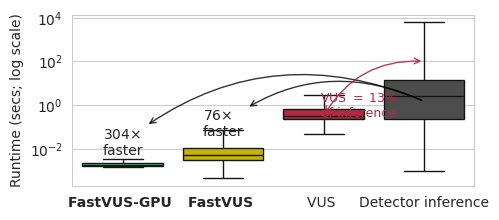

In [17]:
# Boxplot: detector inference (all detectors pooled) vs the 3 VUS metrics, with arrows
metric_cols = ['VUS (L: 128)', f'{my_vus_name} (L: 128)', f'{my_vus_name}-GPU (L: 128)']

box_df = pd.concat([
    merged[['Detector time']].rename(columns={'Detector time': 'Metric time'}).assign(Metric='Detector inference'),
    *[merged[[m]].rename(columns={m: 'Metric time'}).assign(Metric=m) for m in metric_cols],
], ignore_index=True)

box_palette = {'Detector inference': '#4d4d4d', **color_palette}
order = box_df.groupby('Metric')['Metric time'].median().sort_values().index.to_list()

plt.figure(figsize=(5.1, 2.3))
axis = sns.boxplot(
    y='Metric time', x='Metric', hue='Metric', data=box_df,
    showfliers=False, log_scale=True, showmeans=False,
    # meanprops=meanprops, medianprops=medianprops,
    palette=box_palette, order=order, saturation=1,
)
axis.set_ylabel('Runtime (secs; log scale)')
axis.set_xlabel('')
axis.tick_params(axis='x', rotation=0)
axis.grid(visible=False, axis='x')

# "Nx faster" arrows on the AutoVUS boxes (same as the small exec-time figure)
for i, metric in enumerate(order):
    if my_vus_name in metric:
        axis.annotate(
            f'{speed_up_dict[metric]:.0f}$\\times$\nfaster',
            xy=(3, 1.5),
            xytext=(i - 0.2, 0.09 + i * 0.6),
            arrowprops=dict(arrowstyle="<-", connectionstyle="arc3,rad=-.3", color='k', alpha=0.8),
            va='top',
        )

# extra arrow: VUS <-> detector, showing VUS was a good fraction of the inference
i_vus, i_det = order.index('VUS (L: 128)'), order.index('Detector inference')
vus_med, det_med = merged['VUS (L: 128)'].median(), merged['Detector time'].median()
axis.annotate(
    '', xy=(i_det, det_med+100), xytext=(i_vus, vus_med),
    arrowprops=dict(arrowstyle="<->", connectionstyle="arc3,rad=-.3", color='#b02a41', alpha=0.9),
)
axis.text((i_vus + i_det) / 2 - 0.15, np.sqrt(vus_med * det_med),
          f'VUS $=$ {100 * vus_med / det_med:.0f}%\nof inference',
          color='#b02a41', ha='center', va='center', fontsize=9)

# bold + trim the AutoVUS tick labels (same as the main figure)
xticklabels = axis.get_xticklabels()
for lbl in xticklabels:
    if my_vus_name in lbl.get_text():
        lbl.set_fontweight('bold')
    if '(L:' in lbl.get_text():
        lbl.set_text(lbl.get_text().replace('(L: 128)', ''))
axis.set_xticks(axis.get_xticks())
axis.set_xticklabels([l.get_text() for l in xticklabels])

finalize_plot(save_fig_path, 'runtime_vs_detector_tsb_boxes')


In [18]:
# I would like to see the fraction of all inferences that is faster than VUS, the fraction where they are equal and the ones that are faster

merged['Inferece vs Evaluation'] = merged.apply(lambda x: 'Faster' if x['Detector time'] < x['VUS (L: 128)'] else 'Slower', axis='columns')
merged

,Time series,Detector,VUS (L: 128),FastVUS (L: 128),FastVUS-GPU (L: 128),Detector time,Inferece vs Evaluation
0,001_NAB_id_1_Facility_tr_1007_1st_2014.csv,AnomalyTransformer,0.113536,0.002825,0.002900,22.070,Slower
1,001_NAB_id_1_Facility_tr_1007_1st_2014.csv,AutoEncoder,0.430118,0.002663,0.002051,3.053,Slower
2,001_NAB_id_1_Facility_tr_1007_1st_2014.csv,CNN,0.434752,0.002640,0.001977,3.117,Slower
3,001_NAB_id_1_Facility_tr_1007_1st_2014.csv,Chronos,0.427510,0.005584,0.002019,13.370,Slower
4,001_NAB_id_1_Facility_tr_1007_1st_2014.csv,Donut,0.429886,0.002444,0.001987,5.118,Slower
...,...,...,...,...,...,...,...
24446,870_OPPORTUNITY_id_29_HumanActivity_tr_1477_1s...,Sub_PCA,0.368913,0.005906,0.002066,0.137,Faster
24447,870_OPPORTUNITY_id_29_HumanActivity_tr_1477_1s...,TimesFM,0.368041,0.007930,0.002028,60.138,Slower
24448,870_OPPORTUNITY_id_29_HumanActivity_tr_1477_1s...,TimesNet,0.370495,0.007885,0.001982,18.927,Slower
24449,870_OPPORTUNITY_id_29_HumanActivity_tr_1477_1s...,TranAD,0.402809,0.022805,0.001946,1.687,Slower


In [19]:
import matplotlib.colors as mc

def darken(color, amount=0.6):
    """amount<1 darkens (0.6 = 60% of original brightness)."""
    r, g, b = mc.to_rgb(color)
    return (r * amount, g * amount, b * amount)

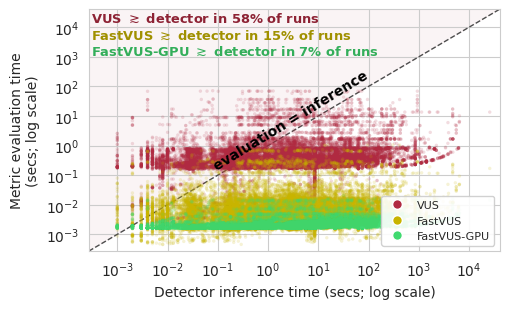

In [20]:
# --- columns (match your palette keys) ---
DET = 'Detector time'
VUS = 'VUS (L: 128)'
CPU = f'{my_vus_name} (L: 128)'        # AutoVUS
GPU = f'{my_vus_name}-GPU (L: 128)'    # AutoVUS-GPU

# clouds to draw, in back-to-front order (slowest first so AutoVUS sits on top)
clouds = [
    (VUS, 'VUS'),
    (CPU, f'{my_vus_name}'),
    (GPU, f'{my_vus_name}-GPU'),   # uncomment to add the GPU cloud
]

fig, ax = plt.subplots(figsize=(5.2, 3.2))

# shared square limits so y=x is a real 45deg line
vals = np.concatenate([merged[DET].values] + [merged[c].values for c, _ in clouds])
lo, hi = vals.min() * 0.6, vals.max() * 1.6
lims = [lo, hi]

# diagonal: evaluation == inference, and shade the "eval is the bottleneck" triangle
ax.fill_between(lims, lims, hi, color=color_palette['VUS (L: 128)'], alpha=0.05, lw=0, zorder=0)
ax.plot(lims, lims, ls='--', lw=1.0, color='#4d4d4d', zorder=1)
gm = 10 ** ((np.log10(lo) + np.log10(hi)) / 2)

fig.canvas.draw()
p0 = ax.transData.transform((lo, lo))
p1 = ax.transData.transform((hi, hi))
diag_angle = np.degrees(np.arctan2(p1[1] - p0[1], p1[0] - p0[0]))
ax.text(gm, gm * 1.35, 'evaluation = inference', rotation=diag_angle,
        rotation_mode='anchor', ha='center', va='bottom',
        fontsize=10, color='#000000', fontweight='bold')


# scatter clouds + median markers
handles = []
for i, (col, label) in enumerate(clouds):
    c = color_palette[col]
    ax.scatter(merged[DET], merged[col], s=6, alpha=0.16, color=c,
               edgecolors='none', rasterized=True, zorder=2)
    # ax.scatter(merged[DET].median(), merged[col].median(), s=110, color=c,
    #            edgecolors='white', linewidths=1.4, zorder=4)
    handles.append(plt.Line2D([], [], marker='o', ls='', ms=7, mec='white',
                              mew=1.0, color=c, label=label))
    frac = (merged[col] >= merged[DET] / 10).mean() * 100
    ax.text(0.005, 0.99 - 0.069 * i,
            f'{col.replace(' (L: 128)', '')} $\\gtrsim$ detector in {frac:.0f}% of runs',
            transform=ax.transAxes, ha='left', va='top', fontsize=9.4, color=darken(c, 0.8), fontweight='semibold')

ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlim(lims); ax.set_ylim(lims)
# ax.set_aspect('equal', adjustable='box')
ax.set_xlabel('Detector inference time (secs; log scale)')
ax.set_ylabel('Metric evaluation time\n(secs; log scale)')
ax.legend(handles=handles, loc='lower right', frameon=True, framealpha=0.9,
          fontsize=8)

finalize_plot(save_fig_path, 'runtime_vs_detector_tsb_scatter')

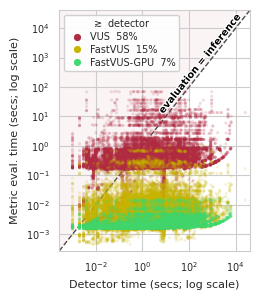

In [ ]:
import matplotlib.patheffects as pe

# --- columns (match your palette keys) ---
DET = 'Detector time'
VUS = 'VUS (L: 128)'
CPU = f'{my_vus_name} (L: 128)'        # AutoVUS
GPU = f'{my_vus_name}-GPU (L: 128)'    # AutoVUS-GPU

clouds = [
    (VUS, 'VUS'),
    (CPU, f'{my_vus_name}'),
    (GPU, f'{my_vus_name}-GPU'),
]

fig, ax = plt.subplots(figsize=(2.7, 3.1))

# shared square limits so y=x is a real diagonal
vals = np.concatenate([merged[DET].values] + [merged[c].values for c, _ in clouds])
lo, hi = vals.min() * 0.6, vals.max() * 1.6
lims = [lo, hi]

# shaded "eval is the bottleneck" triangle + y=x diagonal
ax.fill_between(lims, lims, hi, color=color_palette[VUS], alpha=0.05, lw=0, zorder=0)
ax.plot(lims, lims, ls='--', lw=1.0, color='#4d4d4d', zorder=1)

# scatter clouds; the per-series "share >= detector" fraction moves into the legend
handles = []
for col, label in clouds:
    c = color_palette[col]
    ax.scatter(merged[DET], merged[col], s=5, alpha=0.16, color=c,
               edgecolors='none', rasterized=True, zorder=2)
    frac = (merged[col] >= merged[DET] / 10).mean() * 100
    handles.append(plt.Line2D([], [], marker='o', ls='', ms=6, mec='white',
                              mew=0.8, color=c, label=f'{label}  {frac:.0f}%'))

ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlim(lims); ax.set_ylim(lims)
ax.set_xlabel('Detector time (secs; log scale)', fontsize=8)
ax.set_ylabel('Metric eval. time (secs; log scale)', fontsize=8)
ax.tick_params(labelsize=7)

# diagonal label, angled to the (now non-square) box diagonal — compute after limits are final
fig.canvas.draw()
p0 = ax.transData.transform((lo, lo))
p1 = ax.transData.transform((hi, hi))
diag_angle = np.degrees(np.arctan2(p1[1] - p0[1], p1[0] - p0[0]))
gm = 10 ** ((np.log10(lo) + np.log10(hi)) / 2)
ax.text(gm*130, gm * 150, 'evaluation = inference', rotation=diag_angle+2.5,
        rotation_mode='anchor', ha='center', va='bottom',
        fontsize=7, color='#000000', fontweight='bold',
        path_effects=[pe.withStroke(linewidth=1.8, foreground='white')])


ax.legend(handles=handles, loc='upper left', frameon=True, framealpha=0.9,
          fontsize=7, title='$\\gtrsim$ detector', title_fontsize=7,
          handletextpad=0.4, labelspacing=0.3, borderpad=0.3)

finalize_plot(save_fig_path, 'runtime_vs_detector_tsb_scatter_small')
